# Final Assignment Tutorial — Telecom

This notebook is a reference walkthrough for the GCI World 2026 Winter final assignment.
The dataset comes from **Company A**, an anonymous telecommunications service provider, and contains historical customer information across two linked tables (`Client.csv`, `Record.csv`).

Your task is to analyze this data, build a machine learning model whose output supports a concrete business proposal — not to build the best possible model.

**What this notebook walks through:**
1. Market context.
2. Loading and merging the two source tables.
3. EDA: shape, missingness, target distribution, and a worked feature example.
4. Problem Definition — choosing the target and the ML task.
5. Preprocessing — what EDA told us we have to do.
6. A baseline churn classifier.
7. Model evaluation and feature importance.
8. From model to business proposal.

> **Treat this as a reference, not a template.** The strongest submissions diverge from it: a different target, a different segment, a different lever. Originality is rewarded.


---

## 1.Introduction & Market Analysis


### 1.1 Company context
*Company A* is a wireless telecommunications operator. They have years of usage and billing data on roughly 100,000 customers but no in-house machine learning capability.

When a company commissions a business proposal, they usually arrive with a vague sense that *something* needs to improve — margins, retention, growth, customer satisfaction — but no clear view of which lever to pull, which segment to focus on, or even which question to start with. **Choosing the question is the analyst's first job, and the rest of the proposal stands or falls on it.** The dataset rarely points to a single obvious answer; it admits several, and which one you pursue determines the kind of recommendation you can make.

This dataset includes a binary `churn` flag — whether a customer left within 31–60 days after the observation date — and we use churn as the worked example throughout this notebook. But churn is one of many viable targets the data supports. **You may and should explore other targets** — revenue, usage, equipment lifecycle, segment-level behaviour. Pick the question whose answer best supports the proposal you want to make.

### 1.2 Why this market matters
- Acquiring a new subscriber costs several times more than keeping one — retention, usage, and ARPU all translate directly into margin.
- Mature, saturated markets grow by taking customers from competitors or lifting revenue per existing customer.
- Behaviour signals (usage decline, complaints, equipment ageing) precede both churn and revenue compression by months.

**Questions to think about:**
- What does the telecom market look like in your country or region — who are the major players, what local dynamics (regulation, technology shifts, new entrants) are reshaping churn, and what story can you tell about a specific market you know? A proposal grounded in a local market you can describe concretely is more compelling than one assembled from generic global figures.
- What recent, citable sources can you find that quantify these claims for your target market? Uncited industry numbers will not strengthen your case.
- What share of churn in this market is voluntary (customer-initiated) versus involuntary (non-payment, address change)? Which one can a model meaningfully address?

---

## 2.Setup and Data Loading


### 2.1 Import libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report, roc_auc_score, roc_curve
)
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier, plot_importance
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
import warnings
warnings.filterwarnings('ignore')

pd.set_option('display.max_columns', 120)
plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette('husl')

print('All libraries loaded successfully.')


All libraries loaded successfully.


### 2.2 Connect to Google Drive

If you are running this notebook on Google Colab, mount your Drive and `cd` into the folder that contains the dataset.


In [2]:
# Run this cell only on Google Colab.
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


**IMPORTANT**:<br>
Change the path in the `%cd` command below to match the folder where this notebook is saved on Google Drive by **replacing "WhereThisNotebookIsLocated" with your actual folder path**.

Example:
- You uploaded `Final Assignment` folder directly under MyDrive (the default folder when you open Google Drive)
    - Change to "/<wbr>content/drive/MyDrive/Final Assignment"

You can easily locate your notebook's directory by:
1. Open the Files panel on the left side of Colab
2. Navigate through the "drive" and "MyDrive" folders until you find your notebook's folders
3. Click the more actions icon (three vertical dots, $\vdots$) next to the folder name
4. Select the option "Copy path"

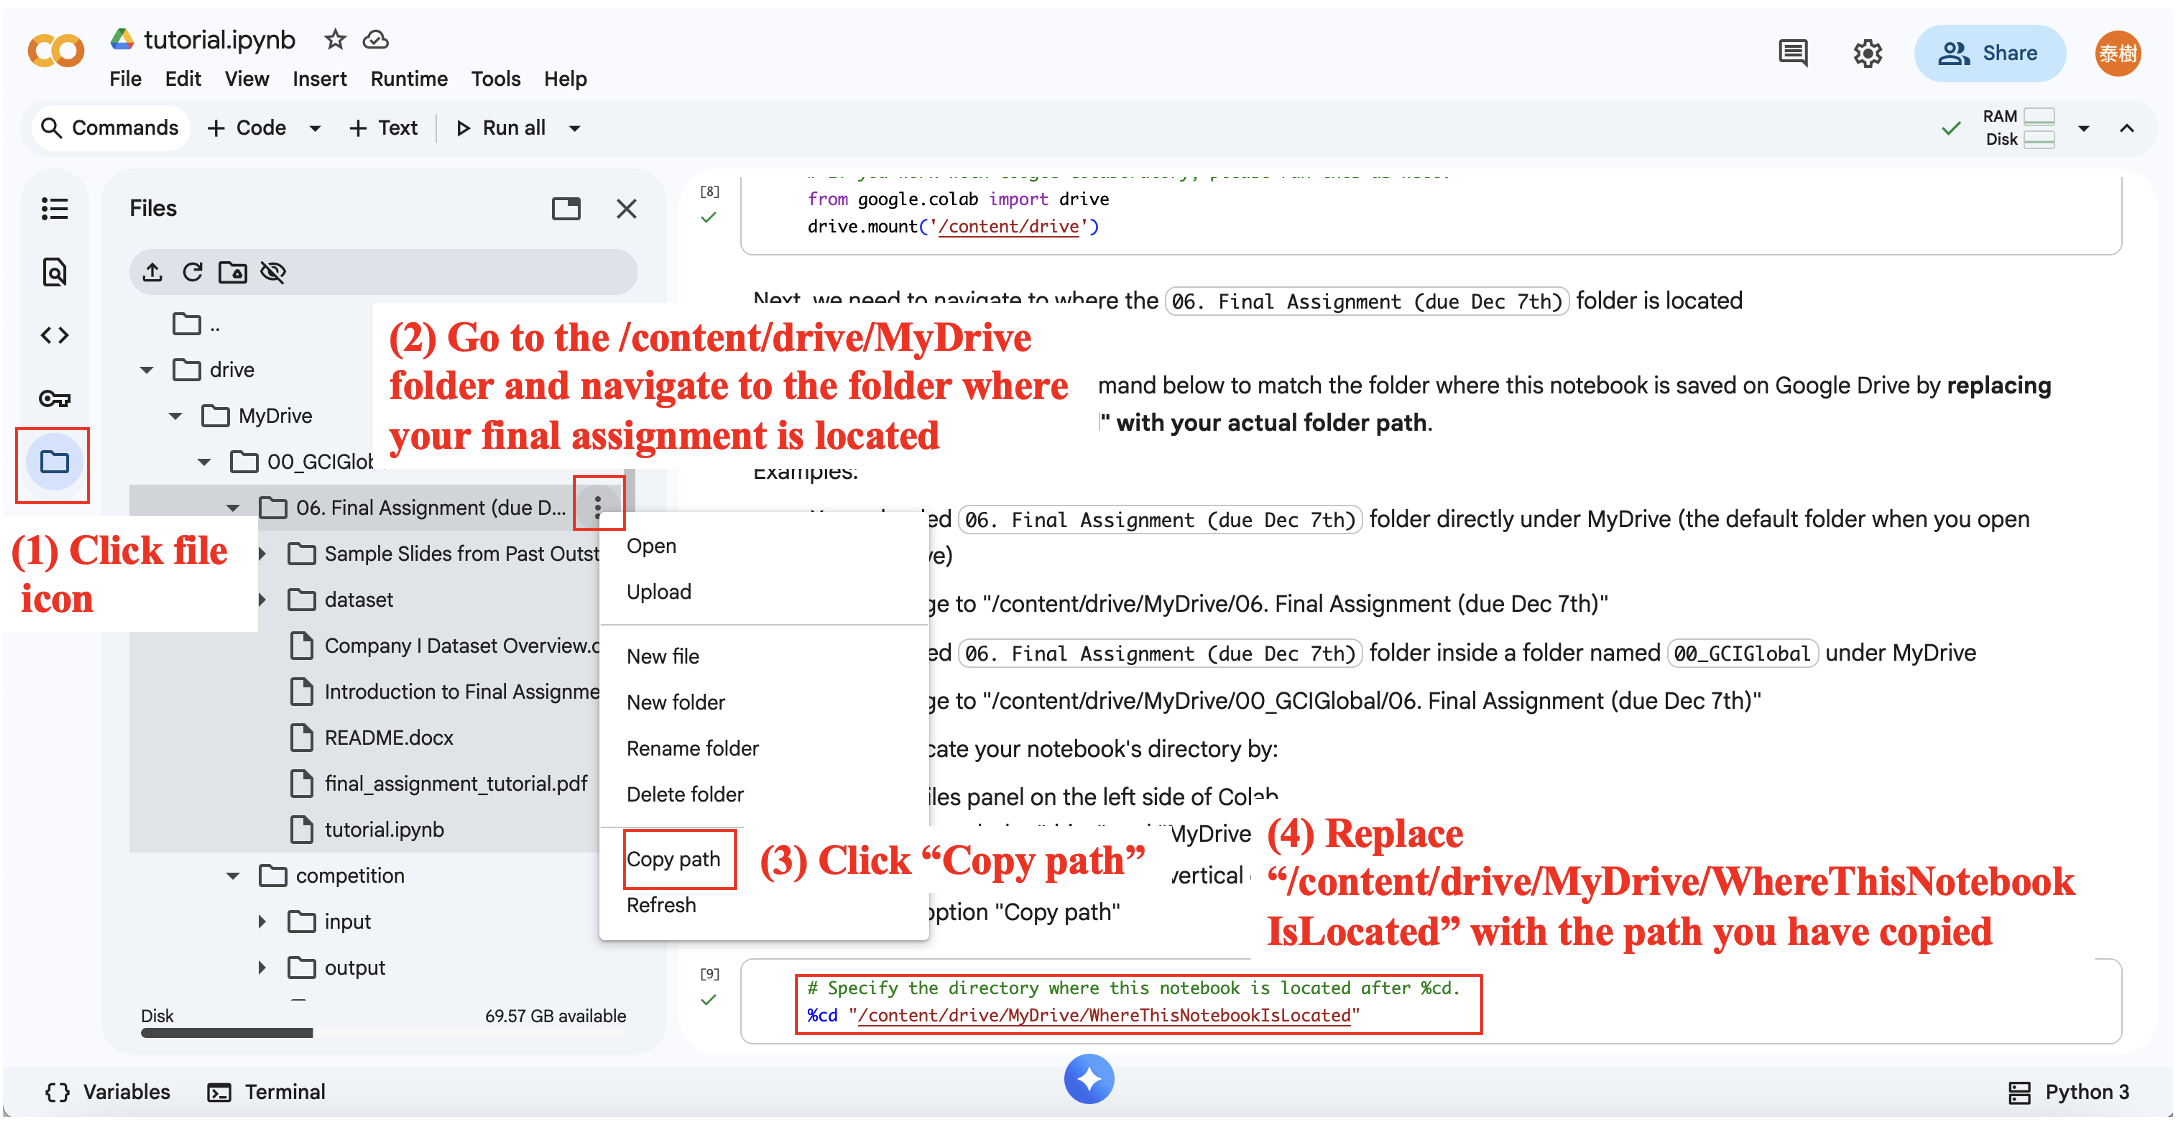

In [3]:
#%cd "/content/drive/MyDrive/WhereThisNotebookIsLocated"
%cd "/content/drive/MyDrive/Final Assignment"

/content/drive/MyDrive/Final Assignment


In [4]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


### 2.3 Load the two source tables

The dataset is split across two files:

| File | Granularity | Contents |
|---|---|---|
| `Client.csv` | one row per customer | account-level info: tenure, plan, demographics, equipment |
| `Record.csv` | one row per customer | mean monthly usage, billing, and call-quality metrics, plus the `churn` target |

Both tables share a `Customer_ID` column, which we use to join them into a single analysis table.


In [5]:
import os
from pathlib import Path

current_dir = Path(os.getcwd())
client_path = current_dir / "telecom" / "Client.csv"
record_path = current_dir / "telecom" / "Record.csv"

for p in (client_path, record_path):
    print(f"{'OK ' if p.exists() else 'MISSING '} {p}")

OK  /content/drive/My Drive/Final Assignment/telecom/Client.csv
OK  /content/drive/My Drive/Final Assignment/telecom/Record.csv


In [6]:
client = pd.read_csv(client_path)
record = pd.read_csv(record_path)

print(f"Client: {client.shape}")
print(f"Record: {record.shape}")
df = record.merge(client, on="Customer_ID", how="inner")
print(f"Merged: {df.shape}")
print(f" churn global: {df['churn'].mean()*100:.2f}%")
df.head()

Client: (100000, 50)
Record: (100000, 51)
Merged: (100000, 100)
 churn global: 49.56%


,rev_Mean,mou_Mean,totmrc_Mean,da_Mean,ovrmou_Mean,ovrrev_Mean,vceovr_Mean,datovr_Mean,roam_Mean,change_mou,change_rev,drop_vce_Mean,drop_dat_Mean,blck_vce_Mean,blck_dat_Mean,unan_vce_Mean,unan_dat_Mean,plcd_vce_Mean,plcd_dat_Mean,recv_vce_Mean,recv_sms_Mean,comp_vce_Mean,comp_dat_Mean,custcare_Mean,ccrndmou_Mean,cc_mou_Mean,inonemin_Mean,threeway_Mean,mou_cvce_Mean,mou_cdat_Mean,mou_rvce_Mean,owylis_vce_Mean,mouowylisv_Mean,iwylis_vce_Mean,mouiwylisv_Mean,peak_vce_Mean,peak_dat_Mean,mou_peav_Mean,mou_pead_Mean,opk_vce_Mean,opk_dat_Mean,mou_opkv_Mean,mou_opkd_Mean,drop_blk_Mean,attempt_Mean,complete_Mean,callfwdv_Mean,callwait_Mean,churn,months,Customer_ID,uniqsubs,actvsubs,new_cell,crclscod,asl_flag,totcalls,totmou,totrev,adjrev,adjmou,adjqty,avgrev,avgmou,avgqty,avg3mou,avg3qty,avg3rev,avg6mou,avg6qty,avg6rev,prizm_social_one,area,dualband,refurb_new,hnd_price,phones,models,hnd_webcap,truck,rv,ownrent,lor,dwlltype,marital,adults,infobase,income,numbcars,HHstatin,dwllsize,forgntvl,ethnic,kid0_2,kid3_5,kid6_10,kid11_15,kid16_17,creditcd,eqpdays
0,23.9975,219.25,22.500,0.2475,0.00,0.0,0.0,0.0,0.0,-157.25,-18.9975,0.666667,0.0,0.666667,0.0,6.333333,0.0,52.333333,0.0,42.333333,0.0,45.000000,0.0,0.000000,0.000000,0.000000,18.000000,0.000000,90.643333,0.0,97.176667,0.000000,0.000000,0.000000,0.000000,58.000000,0.0,132.600000,0.0,24.000000,0.0,55.220000,0.0,1.333333,52.333333,45.000000,0.0,0.333333,1,61,1000001,2,1,U,A,N,1652,4228.00000,1504.62,1453.44,4085.00,1602,29.66,83.37,32.69,272,116,30,322.0,136.0,38.0,S,NORTHWEST/ROCKY MOUNTAIN AREA,Y,N,149.98999,2.0,2.0,WCMB,0.0,0.0,O,15.0,S,S,1.0,M,4.0,3.0,C,A,0.0,N,U,U,U,U,U,Y,361.0
1,57.4925,482.75,37.425,0.2475,22.75,9.1,9.1,0.0,0.0,532.25,50.9875,8.333333,0.0,1.000000,0.0,61.333333,0.0,263.333333,0.0,69.000000,0.0,193.333333,0.0,1.666667,6.333333,5.463333,53.000000,0.333333,189.396667,0.0,55.280000,46.333333,24.216667,6.333333,3.696667,83.666667,0.0,75.333333,0.0,157.000000,0.0,169.343333,0.0,9.333333,263.333333,193.333333,0.0,5.666667,0,56,1000002,1,1,N,EA,N,14654,26400.00000,2851.68,2833.88,26367.00,14624,51.53,479.40,265.89,305,158,40,477.0,275.0,48.0,U,CHICAGO AREA,N,N,NaN,7.0,6.0,WC,1.0,1.0,NaN,1.0,S,S,1.0,M,5.0,1.0,C,A,0.0,Z,U,U,U,U,U,Y,240.0
2,16.9900,10.25,16.990,0.0000,0.00,0.0,0.0,0.0,0.0,-4.25,0.0000,0.333333,0.0,0.000000,0.0,2.666667,0.0,9.000000,0.0,0.333333,0.0,6.000000,0.0,0.000000,0.000000,0.000000,0.333333,0.000000,5.426667,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,5.000000,0.0,5.193333,0.0,1.000000,0.0,0.233333,0.0,0.333333,9.000000,6.000000,0.0,0.000000,1,58,1000003,1,1,Y,C,N,7903,24385.05333,2155.91,1934.47,24303.05,7888,34.54,433.98,140.86,12,7,17,11.0,6.0,17.0,S,GREAT LAKES AREA,N,N,29.98999,2.0,1.0,NaN,0.0,0.0,O,7.0,S,M,2.0,M,5.0,2.0,C,A,0.0,N,U,Y,U,U,U,Y,1504.0
3,38.0000,7.50,38.000,0.0000,0.00,0.0,0.0,0.0,0.0,-1.50,0.0000,0.000000,0.0,0.000000,0.0,0.000000,0.0,3.666667,0.0,1.333333,0.0,3.666667,0.0,0.000000,0.000000,0.000000,1.333333,0.000000,8.410000,0.0,0.413333,0.333333,0.256667,0.000000,0.000000,1.333333,0.0,3.380000,0.0,3.666667,0.0,5.450000,0.0,0.000000,3.666667,3.666667,0.0,0.000000,0,60,1000004,1,1,Y,B,N,1502,3065.00000,2000.90,1941.81,3035.00,1479,40.45,63.23,30.81,8,3,38,50.0,25.0,40.0,T,CHICAGO AREA,N,N,29.98999,1.0,1.0,NaN,0.0,0.0,NaN,6.0,M,M,4.0,M,6.0,1.0,C,D,0.0,U,Y,U,U,U,U,Y,1812.0
4,55.2300,570.50,71.980,0.0000,0.00,0.0,0.0,0.0,0.0,38.50,0.0000,9.666667,0.0,0.666667,0.0,77.000000,0.0,222.333333,0.0,94.666667,0.0,137.000000,0.0,8.666667,15.000000,11.076667,66.000000,0.000000,285.233333,0.0,106.330000,14.666667,10.816667,0.666667,0.366667,97.333333,0.0,173.476667,0.0,90.333333,0.0,218.086667,0.0,10.333333,222.333333,137.000000,0.0,0.000000,0,57,1000005,1,1,Y,A,N,4485,14028.00000,2181.12,2166.48,13965.00,4452,38.69,249.38,79.50,558,191,55,586.0,196.0,80.0,U,NEW ENGLAND AREA,Y,N,149.98999,6.0,4.0,WCMB,0.0,0.0,R,5.0,M,S,1.0,M,6.0,1.0,C,O,0.0,I,U,U,U,U,U,Y,434.0


In [7]:
# Merge on Customer_ID. Both tables have one row per customer, so this is a 1:1 join.
df = record.merge(client, on='Customer_ID', how='inner',validate='one_to_one')
print(f"Merged: {df.shape}")
df.head()

Merged: (100000, 100)


,rev_Mean,mou_Mean,totmrc_Mean,da_Mean,ovrmou_Mean,ovrrev_Mean,vceovr_Mean,datovr_Mean,roam_Mean,change_mou,change_rev,drop_vce_Mean,drop_dat_Mean,blck_vce_Mean,blck_dat_Mean,unan_vce_Mean,unan_dat_Mean,plcd_vce_Mean,plcd_dat_Mean,recv_vce_Mean,recv_sms_Mean,comp_vce_Mean,comp_dat_Mean,custcare_Mean,ccrndmou_Mean,cc_mou_Mean,inonemin_Mean,threeway_Mean,mou_cvce_Mean,mou_cdat_Mean,mou_rvce_Mean,owylis_vce_Mean,mouowylisv_Mean,iwylis_vce_Mean,mouiwylisv_Mean,peak_vce_Mean,peak_dat_Mean,mou_peav_Mean,mou_pead_Mean,opk_vce_Mean,opk_dat_Mean,mou_opkv_Mean,mou_opkd_Mean,drop_blk_Mean,attempt_Mean,complete_Mean,callfwdv_Mean,callwait_Mean,churn,months,Customer_ID,uniqsubs,actvsubs,new_cell,crclscod,asl_flag,totcalls,totmou,totrev,adjrev,adjmou,adjqty,avgrev,avgmou,avgqty,avg3mou,avg3qty,avg3rev,avg6mou,avg6qty,avg6rev,prizm_social_one,area,dualband,refurb_new,hnd_price,phones,models,hnd_webcap,truck,rv,ownrent,lor,dwlltype,marital,adults,infobase,income,numbcars,HHstatin,dwllsize,forgntvl,ethnic,kid0_2,kid3_5,kid6_10,kid11_15,kid16_17,creditcd,eqpdays
0,23.9975,219.25,22.500,0.2475,0.00,0.0,0.0,0.0,0.0,-157.25,-18.9975,0.666667,0.0,0.666667,0.0,6.333333,0.0,52.333333,0.0,42.333333,0.0,45.000000,0.0,0.000000,0.000000,0.000000,18.000000,0.000000,90.643333,0.0,97.176667,0.000000,0.000000,0.000000,0.000000,58.000000,0.0,132.600000,0.0,24.000000,0.0,55.220000,0.0,1.333333,52.333333,45.000000,0.0,0.333333,1,61,1000001,2,1,U,A,N,1652,4228.00000,1504.62,1453.44,4085.00,1602,29.66,83.37,32.69,272,116,30,322.0,136.0,38.0,S,NORTHWEST/ROCKY MOUNTAIN AREA,Y,N,149.98999,2.0,2.0,WCMB,0.0,0.0,O,15.0,S,S,1.0,M,4.0,3.0,C,A,0.0,N,U,U,U,U,U,Y,361.0
1,57.4925,482.75,37.425,0.2475,22.75,9.1,9.1,0.0,0.0,532.25,50.9875,8.333333,0.0,1.000000,0.0,61.333333,0.0,263.333333,0.0,69.000000,0.0,193.333333,0.0,1.666667,6.333333,5.463333,53.000000,0.333333,189.396667,0.0,55.280000,46.333333,24.216667,6.333333,3.696667,83.666667,0.0,75.333333,0.0,157.000000,0.0,169.343333,0.0,9.333333,263.333333,193.333333,0.0,5.666667,0,56,1000002,1,1,N,EA,N,14654,26400.00000,2851.68,2833.88,26367.00,14624,51.53,479.40,265.89,305,158,40,477.0,275.0,48.0,U,CHICAGO AREA,N,N,NaN,7.0,6.0,WC,1.0,1.0,NaN,1.0,S,S,1.0,M,5.0,1.0,C,A,0.0,Z,U,U,U,U,U,Y,240.0
2,16.9900,10.25,16.990,0.0000,0.00,0.0,0.0,0.0,0.0,-4.25,0.0000,0.333333,0.0,0.000000,0.0,2.666667,0.0,9.000000,0.0,0.333333,0.0,6.000000,0.0,0.000000,0.000000,0.000000,0.333333,0.000000,5.426667,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,5.000000,0.0,5.193333,0.0,1.000000,0.0,0.233333,0.0,0.333333,9.000000,6.000000,0.0,0.000000,1,58,1000003,1,1,Y,C,N,7903,24385.05333,2155.91,1934.47,24303.05,7888,34.54,433.98,140.86,12,7,17,11.0,6.0,17.0,S,GREAT LAKES AREA,N,N,29.98999,2.0,1.0,NaN,0.0,0.0,O,7.0,S,M,2.0,M,5.0,2.0,C,A,0.0,N,U,Y,U,U,U,Y,1504.0
3,38.0000,7.50,38.000,0.0000,0.00,0.0,0.0,0.0,0.0,-1.50,0.0000,0.000000,0.0,0.000000,0.0,0.000000,0.0,3.666667,0.0,1.333333,0.0,3.666667,0.0,0.000000,0.000000,0.000000,1.333333,0.000000,8.410000,0.0,0.413333,0.333333,0.256667,0.000000,0.000000,1.333333,0.0,3.380000,0.0,3.666667,0.0,5.450000,0.0,0.000000,3.666667,3.666667,0.0,0.000000,0,60,1000004,1,1,Y,B,N,1502,3065.00000,2000.90,1941.81,3035.00,1479,40.45,63.23,30.81,8,3,38,50.0,25.0,40.0,T,CHICAGO AREA,N,N,29.98999,1.0,1.0,NaN,0.0,0.0,NaN,6.0,M,M,4.0,M,6.0,1.0,C,D,0.0,U,Y,U,U,U,U,Y,1812.0
4,55.2300,570.50,71.980,0.0000,0.00,0.0,0.0,0.0,0.0,38.50,0.0000,9.666667,0.0,0.666667,0.0,77.000000,0.0,222.333333,0.0,94.666667,0.0,137.000000,0.0,8.666667,15.000000,11.076667,66.000000,0.000000,285.233333,0.0,106.330000,14.666667,10.816667,0.666667,0.366667,97.333333,0.0,173.476667,0.0,90.333333,0.0,218.086667,0.0,10.333333,222.333333,137.000000,0.0,0.000000,0,57,1000005,1,1,Y,A,N,4485,14028.00000,2181.12,2166.48,13965.00,4452,38.69,249.38,79.50,558,191,55,586.0,196.0,80.0,U,NEW ENGLAND AREA,Y,N,149.98999,6.0,4.0,WCMB,0.0,0.0,R,5.0,M,S,1.0,M,6.0,1.0,C,O,0.0,I,U,U,U,U,U,Y,434.0


---

## 3.Exploratory Data Analysis

Before modeling, three questions need answers:

1. **How big and structured is the data?** Rows, columns, dtypes.
2. **Where is the data incomplete or unreliable?**
3. **What does the target variable look like?**

Each answer constrains the next step. The shape and types tell us what preprocessing is required. The missingness tells us which columns may need to be dropped, imputed, or treated specially. The target distribution tells us which metrics will be meaningful.

EDA is also where the proposal starts to take shape — the patterns you see now become candidate signals for the model and anchors for the story your proposal will tell. The visualizations in this tutorial are intentionally minimal — just enough to make a point; for your proposal slides, you will want to polish them.

### 3.1 Shape and types

`df.info(verbose=False)` reports total rows, total columns, the count of columns of each dtype, and memory use. Two things to read from the output:

- **Dataset size.** Small enough to keep in pandas — no chunking needed.
- **Dtype mix.** Some columns may be stored as `object` (text). Most machine learning models can only learn from numbers, so any text columns will need to be converted to numeric form before modeling.

In [8]:

df.info(verbose=False)
print(f"\nTotal customers: {df.shape[0]:,}")
print(f"Total features: {df.shape[1]}")

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Columns: 100 entries, rev_Mean to eqpdays
dtypes: float64(69), int64(10), object(21)
memory usage: 76.3+ MB

Total customers: 100,000
Total features: 100


### 3.2 Missing values

A column that is mostly missing carries little signal — dropping it is often cleaner than trying to impute. We count the missing values in each column, take the 20 worst, and plot them.

Columns with missing values:
                  missing   pct
numbcars            49366  49.4
dwllsize            38308  38.3
HHstatin            37923  37.9
ownrent             33706  33.7
dwlltype            31909  31.9
lor                 30190  30.2
income              25436  25.4
adults              23019  23.0
infobase            22079  22.1
hnd_webcap          10189  10.2
prizm_social_one     7388   7.4
avg6qty              2839   2.8
avg6rev              2839   2.8
avg6mou              2839   2.8
kid3_5               1732   1.7
ethnic               1732   1.7
kid0_2               1732   1.7
marital              1732   1.7
forgntvl             1732   1.7
creditcd             1732   1.7
kid16_17             1732   1.7
truck                1732   1.7
kid6_10              1732   1.7
kid11_15             1732   1.7
rv                   1732   1.7
change_mou            891   0.9
change_rev            891   0.9
hnd_price             847   0.8
datovr_Mean           357   0.4
ovrrev_Mean

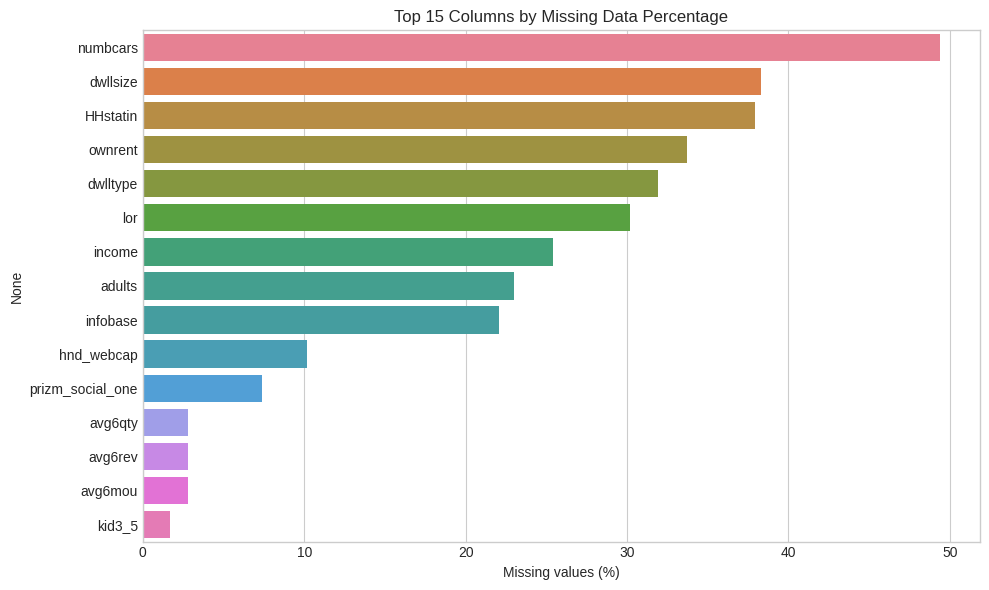

In [9]:

missing_counts = df.isna().sum()
missing_pct = (missing_counts / len(df) * 100).round(1)
missing_df = pd.DataFrame({'missing': missing_counts, 'pct': missing_pct})
missing_df = missing_df[missing_df['missing'] > 0].sort_values('pct', ascending=False)

print('Columns with missing values:')
print(missing_df.to_string())

# Visualize top 15
plt.figure(figsize=(10, 6))
top_missing = missing_df.head(15)
sns.barplot(x=top_missing['pct'], y=top_missing.index, hue=top_missing.index, legend=False)
plt.xlabel('Missing values (%)')
plt.title('Top 15 Columns by Missing Data Percentage')
plt.tight_layout()
plt.show()

### 3.3 Target variable: churn

We'll use `churn` as the worked example. Before modeling we need its class balance — whether stayers and churners appear in roughly equal numbers, or whether one class dominates. The balance directly affects which evaluation metric will be meaningful: accuracy is informative only when classes are balanced; with 5% churn it would be misleading.

Churn distribution:
churn
0    50438
1    49562
Name: count, dtype: int64

churn
0    50.44
1    49.56
Name: proportion, dtype: float64


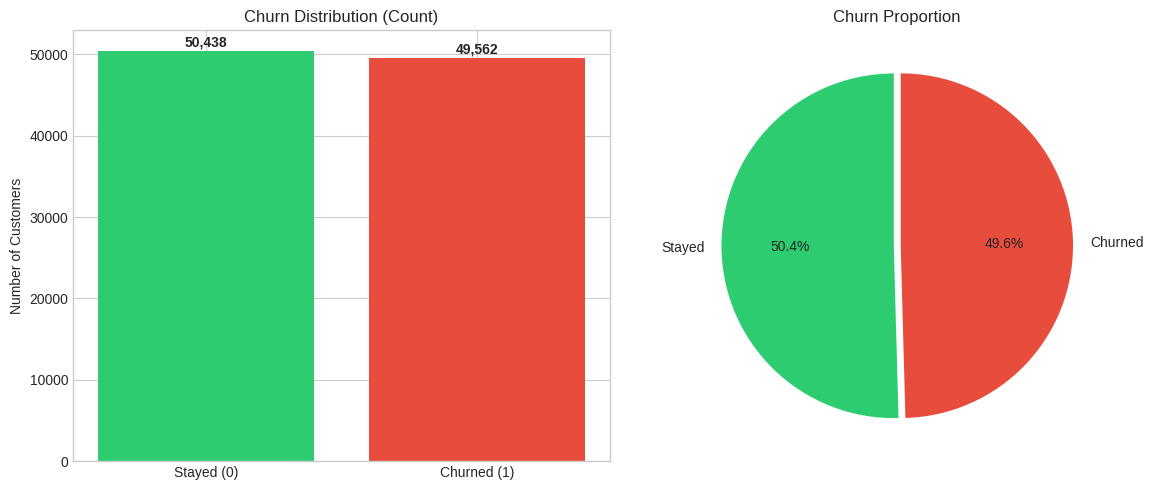

In [10]:
print('Churn distribution:')
print(df['churn'].value_counts())
print()
print(df['churn'].value_counts(normalize=True).round(4) * 100)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Bar chart
counts = df['churn'].value_counts().sort_index()
axes[0].bar(['Stayed (0)', 'Churned (1)'], counts.values, color=['#2ecc71', '#e74c3c'])
axes[0].set_title('Churn Distribution (Count)')
axes[0].set_ylabel('Number of Customers')
for i, v in enumerate(counts.values):
    axes[0].text(i, v + 500, f'{v:,}', ha='center', fontweight='bold')

# Pie chart
axes[1].pie(counts.values, labels=['Stayed', 'Churned'], autopct='%1.1f%%',
            colors=['#2ecc71', '#e74c3c'], startangle=90, explode=(0.02, 0.02))
axes[1].set_title('Churn Proportion')

plt.tight_layout()
plt.show()

Churn is near 50% — unusually balanced for telecom (real-world datasets are typically 5–10% churn). For this dataset, accuracy will be a meaningful metric, and a model that always predicts one class will score around 0.5. If you choose a different target, redo this balance check before picking your evaluation metric.

3.4 Defining High-Value Customers
We define high-value customers as those in the top 25th percentile of monthly revenue (rev_Mean). This segment is critical because they generate a disproportionate share of total revenue, and losing them has an outsized financial impact.

In [11]:
# Define high-value threshold
hv_threshold = df['rev_Mean'].quantile(0.75)
print(f'High-Value Threshold (75th percentile of monthly revenue): ${hv_threshold:.2f}')

df['is_high_value'] = (df['rev_Mean'] >= hv_threshold).astype(int)

hv = df[df['is_high_value'] == 1].copy()
lv = df[df['is_high_value'] == 0].copy()

print(f'\nHigh-Value Customers: {len(hv):,} ({len(hv)/len(df)*100:.1f}%)')
print(f'  - Monthly revenue range: ${hv["rev_Mean"].min():.2f} - ${hv["rev_Mean"].max():.2f}')
print(f'  - Mean monthly revenue: ${hv["rev_Mean"].mean():.2f}')
print(f'  - Churn rate: {hv["churn"].mean()*100:.1f}%')
print(f'\nLower-Value Customers: {len(lv):,} ({len(lv)/len(df)*100:.1f}%)')
print(f'  - Mean monthly revenue: ${lv["rev_Mean"].mean():.2f}')
print(f'  - Churn rate: {lv["churn"].mean()*100:.1f}%')

# Revenue concentration
hv_total_rev = hv['totrev'].sum()
total_rev = df['totrev'].sum()
print(f'\n--- Revenue Concentration ---')
print(f'High-Value total lifetime revenue: ${hv_total_rev:,.0f}')
print(f'Overall total lifetime revenue: ${total_rev:,.0f}')
print(f'HV share of total revenue: {hv_total_rev/total_rev*100:.1f}%')
print(f'(High-value customers are {len(hv)/len(df)*100:.0f}% of the base but generate {hv_total_rev/total_rev*100:.0f}% of revenue)')


High-Value Threshold (75th percentile of monthly revenue): $70.75

High-Value Customers: 24,913 (24.9%)
  - Monthly revenue range: $70.75 - $3843.26
  - Mean monthly revenue: $114.03
  - Churn rate: 48.6%

Lower-Value Customers: 75,087 (75.1%)
  - Mean monthly revenue: $40.28
  - Churn rate: 49.9%

--- Revenue Concentration ---
High-Value total lifetime revenue: $41,633,992
Overall total lifetime revenue: $103,192,499
HV share of total revenue: 40.3%
(High-value customers are 25% of the base but generate 40% of revenue)


3.5 Revenue Distribution & the High-Value Segment

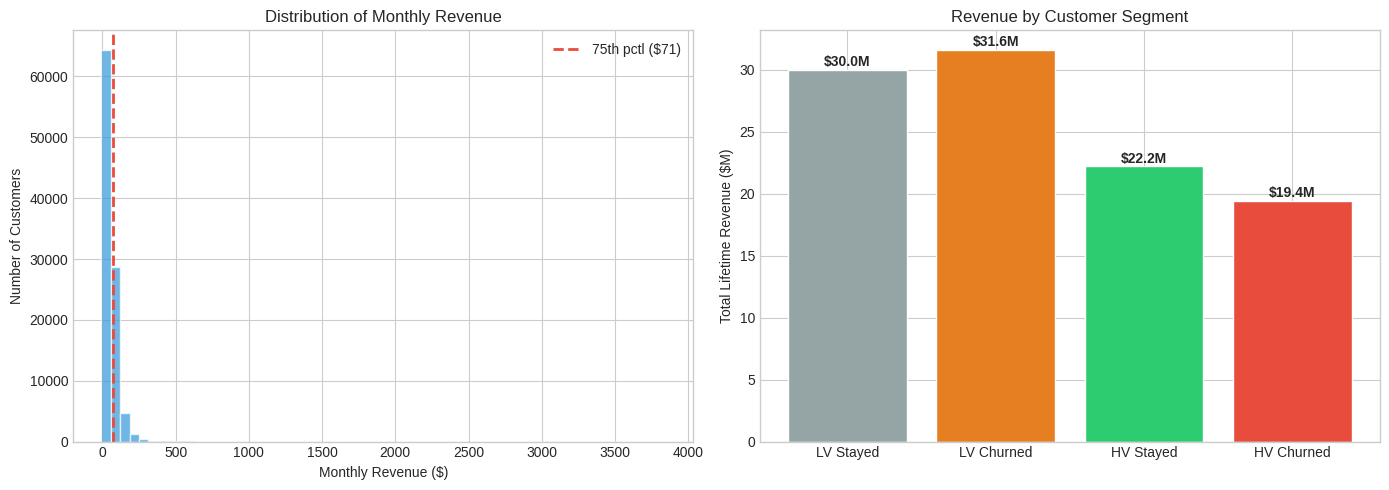

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Revenue distribution
axes[0].hist(df['rev_Mean'], bins=60, color='#3498db', alpha=0.7, edgecolor='white')
axes[0].axvline(hv_threshold, color='#e74c3c', linestyle='--', linewidth=2, label=f'75th pctl (${hv_threshold:.0f})')
axes[0].set_xlabel('Monthly Revenue ($)')
axes[0].set_ylabel('Number of Customers')
axes[0].set_title('Distribution of Monthly Revenue')
axes[0].legend()

# Revenue by segment
seg_data = [
    lv[lv['churn']==0]['totrev'].sum() / 1e6,
    lv[lv['churn']==1]['totrev'].sum() / 1e6,
    hv[hv['churn']==0]['totrev'].sum() / 1e6,
    hv[hv['churn']==1]['totrev'].sum() / 1e6,
]
seg_labels = ['LV Stayed', 'LV Churned', 'HV Stayed', 'HV Churned']
seg_colors = ['#95a5a6', '#e67e22', '#2ecc71', '#e74c3c']

bars = axes[1].bar(seg_labels, seg_data, color=seg_colors, edgecolor='white')
axes[1].set_ylabel('Total Lifetime Revenue ($M)')
axes[1].set_title('Revenue by Customer Segment')
for bar, val in zip(bars, seg_data):
    axes[1].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.3,
                 f'${val:.1f}M', ha='center', fontweight='bold')

plt.tight_layout()
plt.show()

3.6 Key Feature Analysis for High-Value Customers
We examine the behavioral and demographic features that differentiate high-value churners from high-value stayers.

In [13]:
# Compare key features between HV stayers and HV churners
key_features = ['rev_Mean', 'mou_Mean', 'months', 'eqpdays', 'custcare_Mean',
                'drop_vce_Mean', 'change_rev', 'ovrrev_Mean', 'totmrc_Mean',
                'roam_Mean', 'blck_vce_Mean']

comparison = pd.DataFrame({
    'Feature': key_features,
    'HV Stayed': [hv[hv['churn']==0][f].mean() for f in key_features],
    'HV Churned': [hv[hv['churn']==1][f].mean() for f in key_features],
})
comparison['Diff'] = comparison['HV Churned'] - comparison['HV Stayed']
comparison['Diff %'] = (comparison['Diff'] / comparison['HV Stayed'].abs() * 100).round(1)
comparison = comparison.round(2)
print(comparison.to_string(index=False))

      Feature  HV Stayed  HV Churned   Diff  Diff %
     rev_Mean     113.32      114.78   1.46     1.3
     mou_Mean    1089.01      997.04 -91.97    -8.4
       months      19.13       18.44  -0.69    -3.6
      eqpdays     278.35      324.48  46.13    16.6
custcare_Mean       3.52        2.81  -0.71   -20.3
drop_vce_Mean      12.01       11.37  -0.65    -5.4
   change_rev      -2.97        1.60   4.57   154.0
  ovrrev_Mean      38.26       43.63   5.37    14.0
  totmrc_Mean      70.97       65.44  -5.53    -7.8
    roam_Mean       2.98        4.04   1.05    35.4
blck_vce_Mean       7.57        7.49  -0.09    -1.1


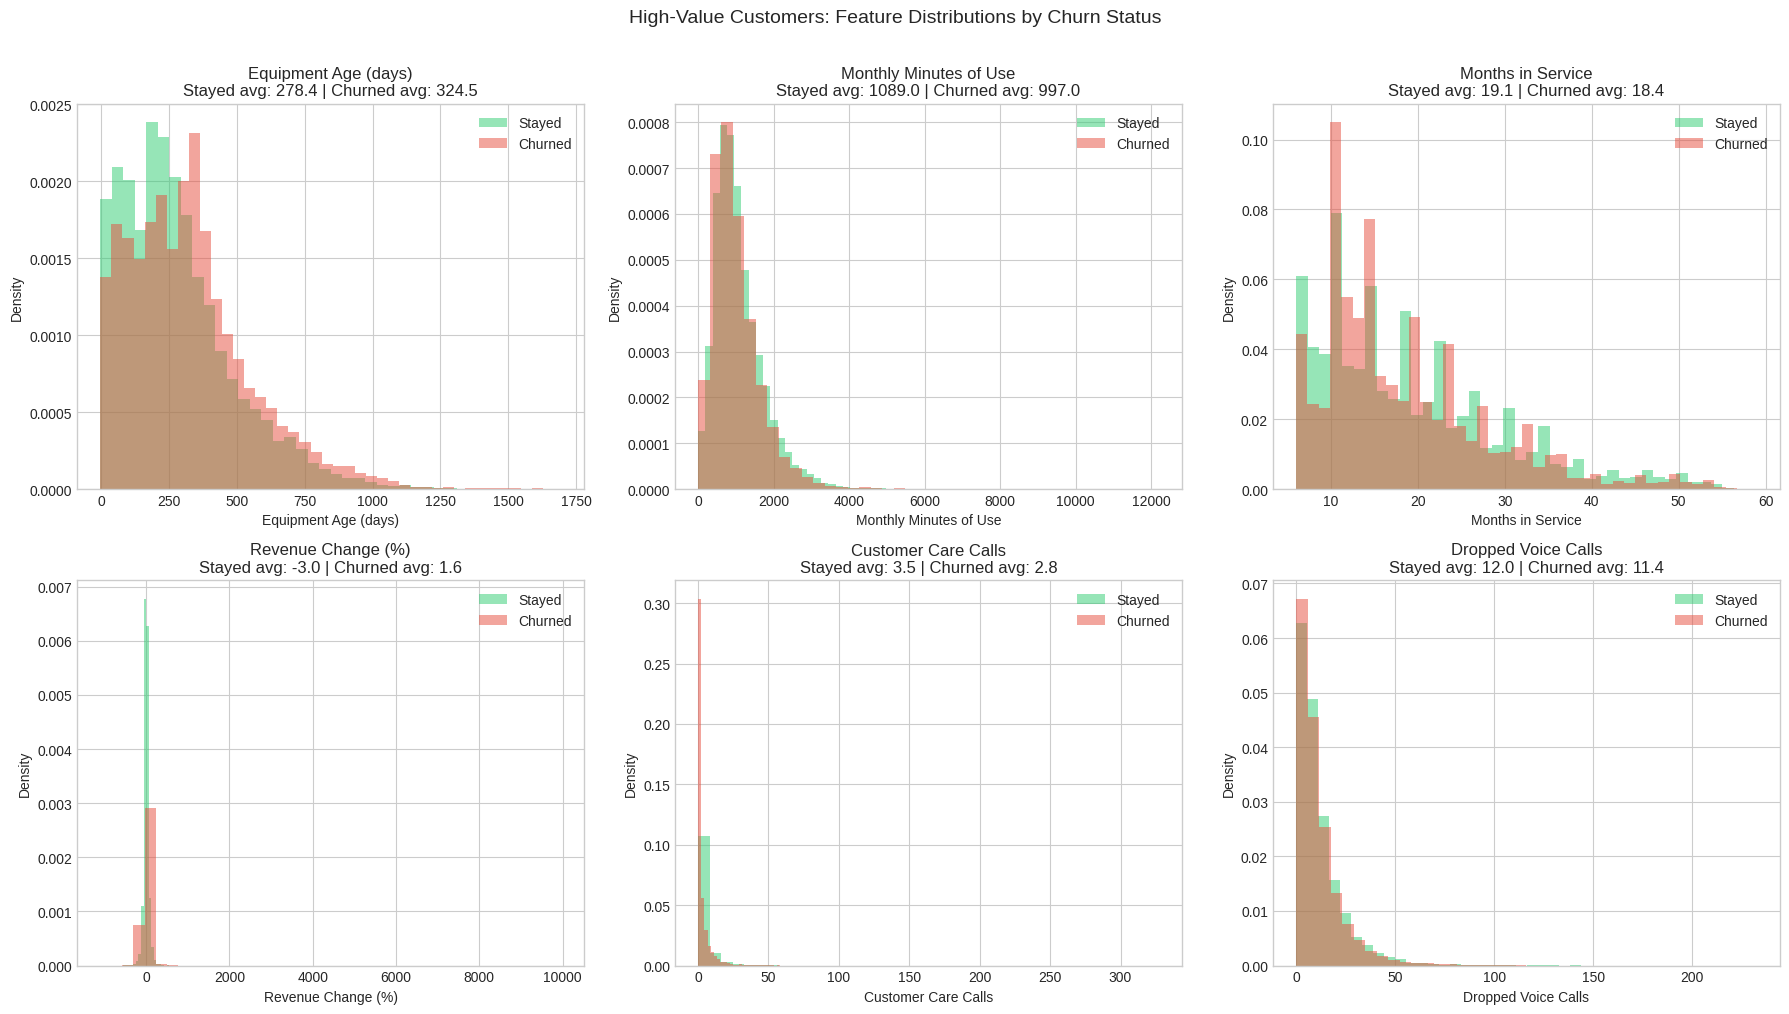

In [14]:
# Visualize key feature comparisons
fig, axes = plt.subplots(2, 3, figsize=(18, 10))

plot_features = [
    ('eqpdays', 'Equipment Age (days)'),
    ('mou_Mean', 'Monthly Minutes of Use'),
    ('months', 'Months in Service'),
    ('change_rev', 'Revenue Change (%)'),
    ('custcare_Mean', 'Customer Care Calls'),
    ('drop_vce_Mean', 'Dropped Voice Calls'),
]

for idx, (feat, title) in enumerate(plot_features):
    ax = axes[idx // 3][idx % 3]
    stayed_vals = hv[hv['churn']==0][feat].dropna()
    churned_vals = hv[hv['churn']==1][feat].dropna()
    ax.hist(stayed_vals, bins=40, alpha=0.5, label='Stayed', color='#2ecc71', density=True)
    ax.hist(churned_vals, bins=40, alpha=0.5, label='Churned', color='#e74c3c', density=True)
    ax.set_title(f'{title}\nStayed avg: {stayed_vals.mean():.1f} | Churned avg: {churned_vals.mean():.1f}')
    ax.set_xlabel(title)
    ax.set_ylabel('Density')
    ax.legend()

plt.suptitle('High-Value Customers: Feature Distributions by Churn Status', fontsize=14, y=1.01)
plt.tight_layout()
plt.show()

##3.7
 Equipment Age vs Churn

Mean equipment age (stayed):  363.3 days
Mean equipment age (churned): 421.1 days


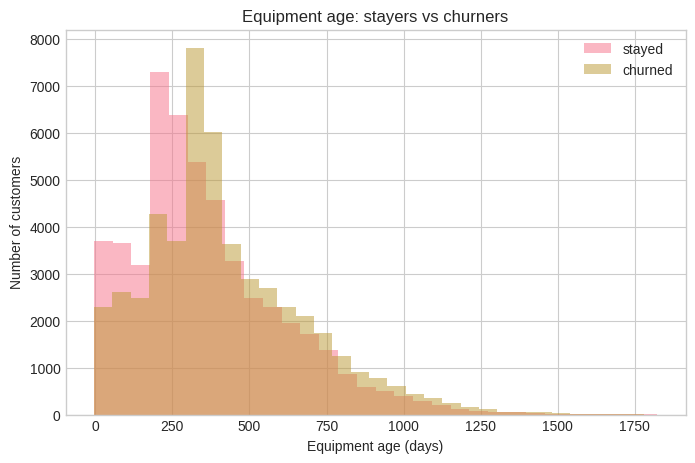

In [15]:
# Split eqpdays into two groups based on churn
stayed = df[df['churn'] == 0]['eqpdays']
churned = df[df['churn'] == 1]['eqpdays']

# Compare the averages
print(f'Mean equipment age (stayed):  {stayed.mean():.1f} days')
print(f'Mean equipment age (churned): {churned.mean():.1f} days')

# Overlay the two distributions
plt.figure(figsize=(8, 5))
plt.hist(stayed, bins=30, alpha=0.5, label='stayed')
plt.hist(churned, bins=30, alpha=0.5, label='churned')
plt.xlabel('Equipment age (days)')
plt.ylabel('Number of customers')
plt.title('Equipment age: stayers vs churners')
plt.legend()
plt.show()

3.9 Correlation Analysis

Top 20 features most correlated with churn (high-value segment):
eqpdays          0.1057
totmrc_Mean     -0.0966
hnd_price       -0.0804
mou_Mean        -0.0701
peak_vce_Mean   -0.0700
mou_rvce_Mean   -0.0686
models          -0.0683
mou_peav_Mean   -0.0681
phones          -0.0678
avg6mou         -0.0677
adjmou          -0.0665
totmou          -0.0662
complete_Mean   -0.0657
avg6qty         -0.0655
comp_vce_Mean   -0.0653
avg3mou         -0.0641
recv_vce_Mean   -0.0639
avg3qty         -0.0635
adjqty          -0.0631
totcalls        -0.0628


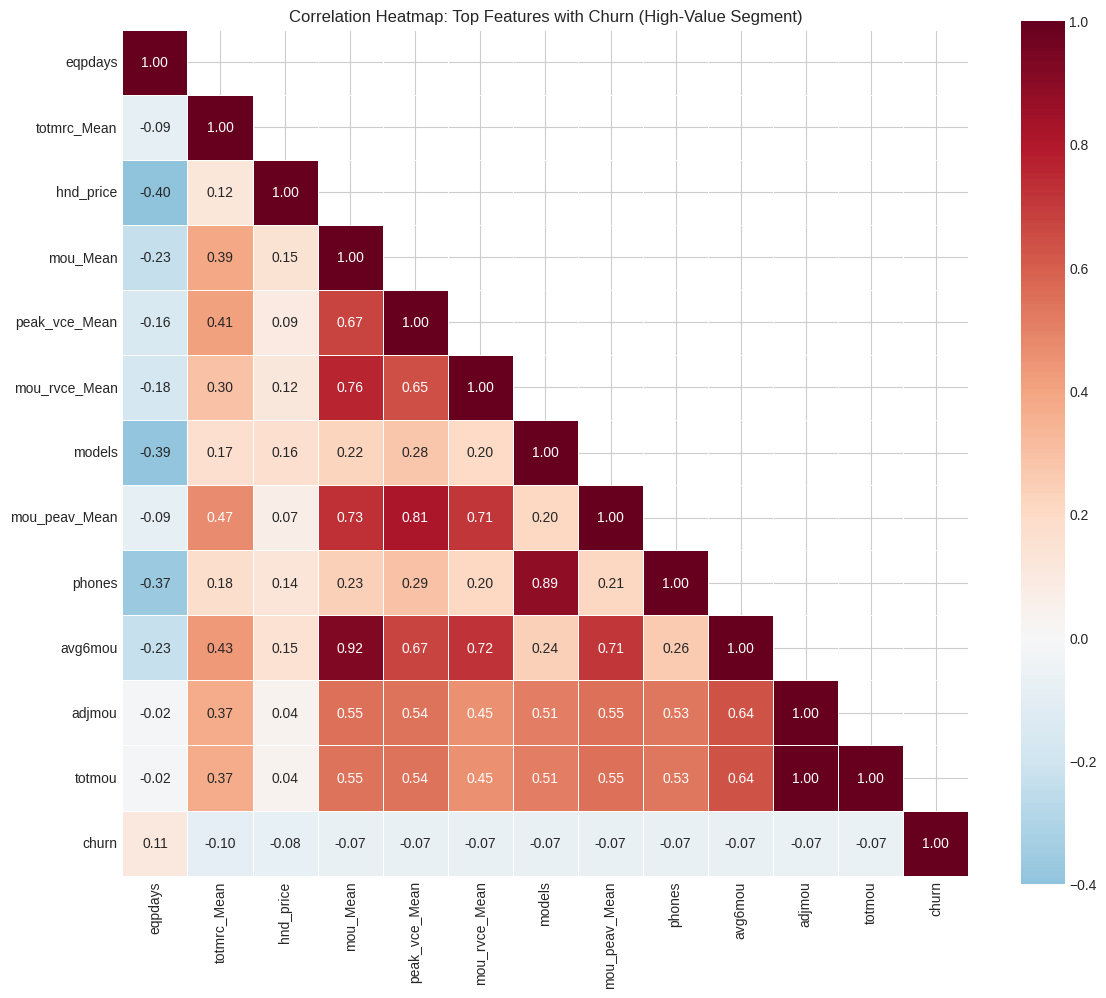

In [16]:
# Correlation of numeric features with churn
numeric_cols = hv.select_dtypes(include=[np.number]).columns
corr_with_churn = hv[numeric_cols].corr()['churn'].drop('churn').sort_values(key=abs, ascending=False)

print('Top 20 features most correlated with churn (high-value segment):')
print(corr_with_churn.head(20).round(4).to_string())

# Heatmap of top correlated features
top_corr_cols = corr_with_churn.head(12).index.tolist() + ['churn']
corr_matrix = hv[top_corr_cols].corr()

plt.figure(figsize=(12, 10))
mask = np.triu(np.ones_like(corr_matrix, dtype=bool), k=1)
sns.heatmap(corr_matrix, mask=mask, annot=True, fmt='.2f', cmap='RdBu_r', center=0,
            square=True, linewidths=0.5)
plt.title('Correlation Heatmap: Top Features with Churn (High-Value Segment)')
plt.tight_layout()
plt.show()

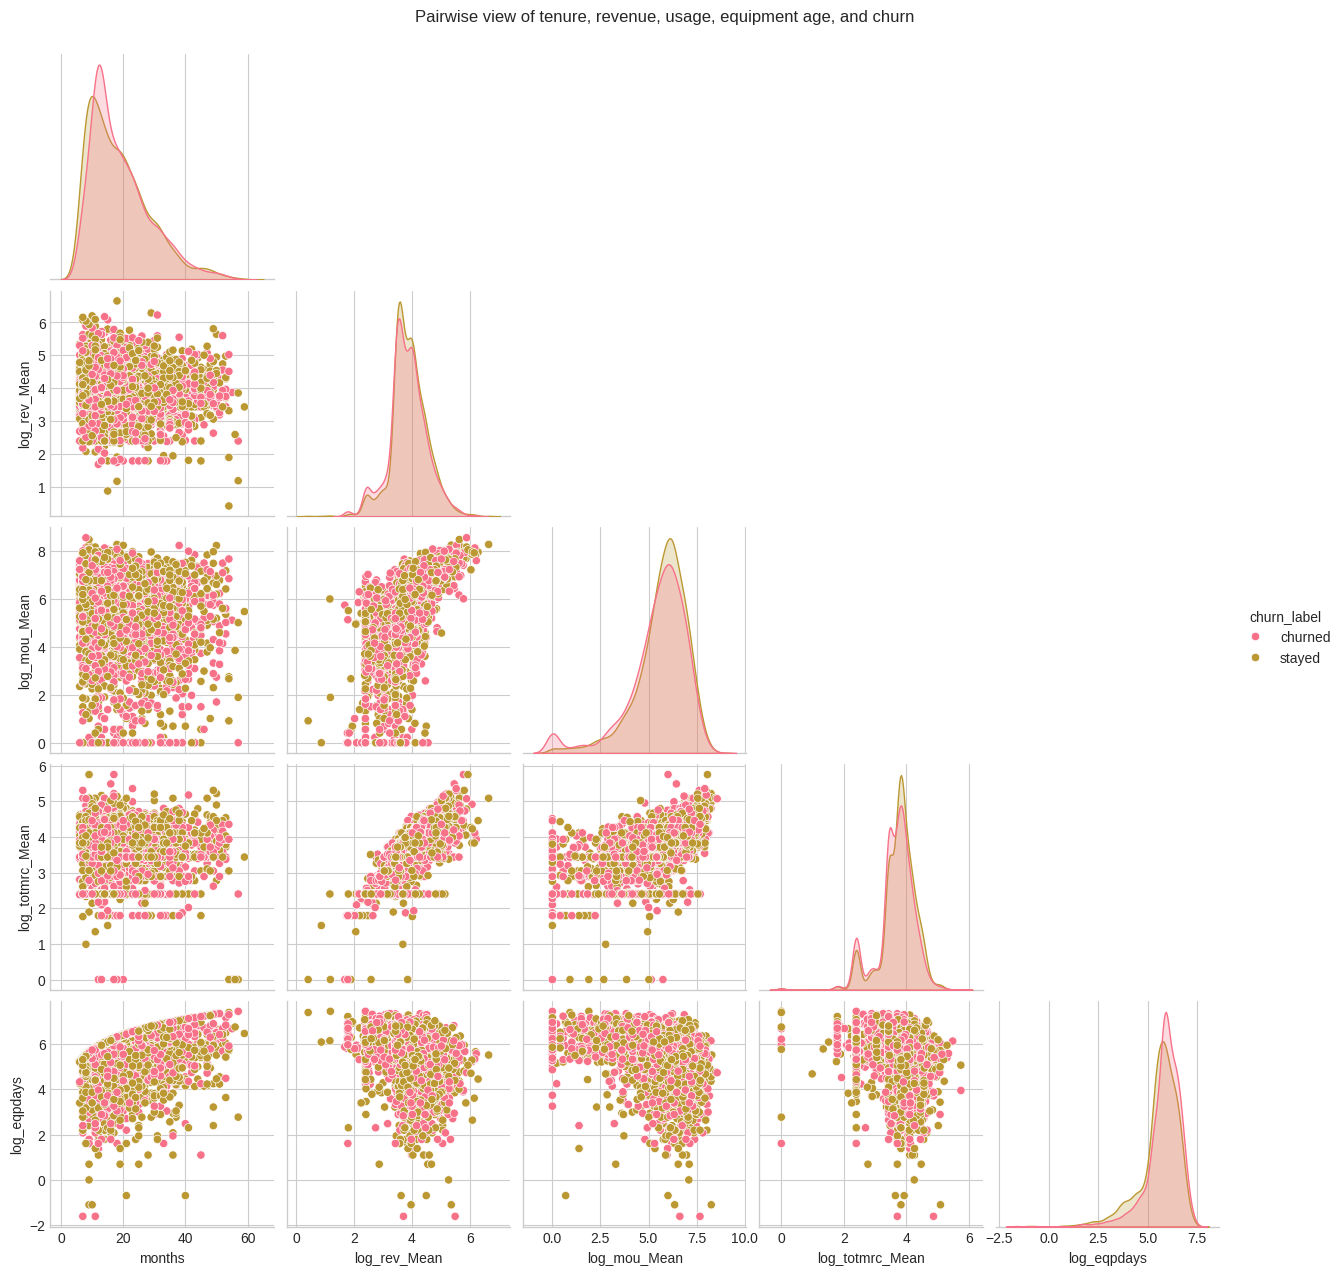

In [17]:
# Select the features for pairwise analysis
plot_df = df[[
    'months',
    'rev_Mean',
    'mou_Mean',
    'totmrc_Mean',
    'eqpdays',
    'churn'
]].dropna().copy()

# Signed log transformation for visualization
def signed_log1p(series):
    return np.sign(series) * np.log1p(np.abs(series))

plot_df['log_rev_Mean'] = signed_log1p(plot_df['rev_Mean'])
plot_df['log_mou_Mean'] = signed_log1p(plot_df['mou_Mean'])
plot_df['log_totmrc_Mean'] = signed_log1p(plot_df['totmrc_Mean'])
plot_df['log_eqpdays'] = signed_log1p(plot_df['eqpdays'])

# Create readable churn labels
plot_df['churn_label'] = plot_df['churn'].map({
    0: 'stayed',
    1: 'churned'
})

# Select columns for the pairplot
pair_cols = [
    'months',
    'log_rev_Mean',
    'log_mou_Mean',
    'log_totmrc_Mean',
    'log_eqpdays',
    'churn_label'
]

# Use a sample of 5000 customers
pair_sample = plot_df[pair_cols].sample(n=5000, random_state=42)

# Generate the pairplot
sns.pairplot(
    pair_sample,
    hue='churn_label',
    corner=True,
    diag_kind='kde',
)

plt.suptitle(
    'Pairwise view of tenure, revenue, usage, equipment age, and churn',
    y=1.02
)

plt.show()

The pairplot does not show a clean geometric separation between churners and non-churners.
This suggests that churn is not explained by a single simple numeric variable such as revenue or usage alone.
However, the diagonal distributions indicate that equipment age (`eqpdays`) is somewhat shifted for churned customers, making it a more interpretable candidate for business intervention.
Revenue- and usage-related variables appear correlated with each other, so they may act as overlapping proxies rather than independent explanations.

## 4. Problem Definition

### 4.1 Problem Statement


We frame the task as a binary classification problem: predict whether a high-value customer will churn (churn = 1) or stay (churn = 0) within 31–60 days of the observation date.

Why this target?

Churn is the most direct measure of customer retention — the core business problem identified in our market analysis.
Focusing on high-value customers maximizes the financial impact of correct predictions.
Early identification (31–60 days ahead) gives Company A enough

### 4.2 Initial Data Preparation

The initial preparation focuses on selecting the high-value customer segment and removing columns that should not be used as model features.

Steps:
- Filter high-value customers using the 75th percentile of monthly revenue.
- Remove Customer_ID and the is_high_value helper column.
- Verify the target variable.
- Inspect missing values and categorical columns.
- Keep the original feature values unchanged for the next preprocessing steps.

In [18]:
# Step 1: Select high-value customers
hv_df = df.loc[df['is_high_value'] == 1].copy()

print(f'High-Value customers: {hv_df.shape[0]:,}')


# Step 2: Remove ID and segmentation helper column
# These columns are not needed as model features.
cols_to_remove = ['Customer_ID', 'is_high_value']

hv_clean = hv_df.drop(columns=cols_to_remove).copy()


# Step 3: Verify the target variable
if hv_clean['churn'].isna().any():
    raise ValueError("The target column contains missing values.")

if not set(hv_clean['churn'].unique()).issubset({0, 1}):
    raise ValueError("Unexpected values found in the churn target.")

print("\nTarget distribution:")
print(hv_clean['churn'].value_counts())


# Step 4: Inspect missing values
# No imputation or column removal is performed here.
missing_summary = pd.DataFrame({
    'Missing Count': hv_clean.isna().sum(),
    'Missing Percentage': hv_clean.isna().mean() * 100
})

missing_summary = missing_summary[
    missing_summary['Missing Count'] > 0
].sort_values('Missing Percentage', ascending=False)

print("\nTop columns with missing values:")
display(missing_summary.head(15).round(2))


# Step 5: Identify categorical columns
object_cols = hv_clean.select_dtypes(
    include=['object', 'category']
).columns.tolist()

print(f"\nNumber of categorical columns: {len(object_cols)}")
print("Categorical columns:", object_cols)


# Step 6: Final inspection
print("\nDataset after initial preparation:")
print("Shape:", hv_clean.shape)
print("Total missing values:", hv_clean.isna().sum().sum())
print("Duplicate rows:", hv_clean.duplicated().sum())

High-Value customers: 24,913

Target distribution:
churn
0    12803
1    12110
Name: count, dtype: int64

Top columns with missing values:


,Missing Count,Missing Percentage
numbcars,13370,53.67
dwllsize,11282,45.29
HHstatin,10888,43.70
ownrent,10041,40.30
dwlltype,9557,38.36
lor,9079,36.44
income,7753,31.12
adults,7034,28.23
infobase,6767,27.16
prizm_social_one,2137,8.58



Number of categorical columns: 21
Categorical columns: ['new_cell', 'crclscod', 'asl_flag', 'prizm_social_one', 'area', 'dualband', 'refurb_new', 'hnd_webcap', 'ownrent', 'dwlltype', 'marital', 'infobase', 'HHstatin', 'dwllsize', 'ethnic', 'kid0_2', 'kid3_5', 'kid6_10', 'kid11_15', 'kid16_17', 'creditcd']

Dataset after initial preparation:
Shape: (24913, 99)
Total missing values: 98312
Duplicate rows: 0


##4.3 Train-Test Split

In [19]:
# Separate features and target
X = hv_clean.drop(columns=['churn']).copy()
y = hv_clean['churn'].copy()

# Stratified train-test split (70/30)
X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.3,
    random_state=42,
    stratify=y
)

# Check dataset sizes
print("Training set:", X_train_raw.shape)
print("Testing set:", X_test_raw.shape)

# Check target distribution
print("\nTraining target distribution:")
print(y_train.value_counts().sort_index())

print("\nTesting target distribution:")
print(y_test.value_counts().sort_index())

Training set: (17439, 98)
Testing set: (7474, 98)

Training target distribution:
churn
0    8962
1    8477
Name: count, dtype: int64

Testing target distribution:
churn
0    3841
1    3633
Name: count, dtype: int64


##4.4 Feature Engineering


Feature engineering is used to create additional variables that may capture meaningful customer behavior.

All engineered features will be created separately for the training and testing sets after the split.

For ratio-based features, non-positive denominators will produce missing values instead of extremely large or invalid ratios. Missing values will be handled later using preprocessing fitted only on the training set.


In [20]:
# Function to create engineered features
def add_engineered_features(data):

    data = data.copy()

    # Safe ratio calculation
    # Non-positive denominators are treated as missing
    def safe_ratio(numerator, denominator):
        valid_denominator = denominator.where(denominator > 0)
        return numerator / valid_denominator

    # 1. Call failure rate
    data['call_failure_rate'] = safe_ratio(
        data['drop_vce_Mean'] + data['blck_vce_Mean'],
        data['attempt_Mean']
    )

    # 2. Customer care intensity per month
    data['custcare_per_month'] = safe_ratio(
        data['custcare_Mean'],
        data['months']
    )

    # 3. Recent usage trend
    data['usage_trend'] = safe_ratio(
        data['avg3mou'],
        data['avgmou']
    )

    # 4. Recent revenue trend
    data['revenue_trend'] = safe_ratio(
        data['avg3rev'],
        data['avgrev']
    )

    # 5. Voice completion rate
    data['voice_completion_rate'] = safe_ratio(
        data['comp_vce_Mean'],
        data['plcd_vce_Mean']
    )

    return data


# Apply feature engineering separately
X_train_fe = add_engineered_features(X_train_raw)
X_test_fe = add_engineered_features(X_test_raw)


# Check the results
engineered_features = [
    'call_failure_rate',
    'custcare_per_month',
    'usage_trend',
    'revenue_trend',
    'voice_completion_rate'
]

print("Training shape:", X_train_fe.shape)
print("Testing shape:", X_test_fe.shape)

print("\nNew features:")
print(engineered_features)

print("\nMissing values in new training features:")
display(X_train_fe[engineered_features].isna().sum())

print("\nTraining feature summary:")
display(X_train_fe[engineered_features].describe().round(3))


Training shape: (17439, 103)
Testing shape: (7474, 103)

New features:
['call_failure_rate', 'custcare_per_month', 'usage_trend', 'revenue_trend', 'voice_completion_rate']

Missing values in new training features:


,0
call_failure_rate,771
custcare_per_month,0
usage_trend,1
revenue_trend,0
voice_completion_rate,771



Training feature summary:


,call_failure_rate,custcare_per_month,usage_trend,revenue_trend,voice_completion_rate
count,16668.000,17439.000,17438.000,17439.000,16668.000
mean,0.071,0.261,1.261,1.236,0.763
std,0.061,0.642,0.498,0.443,0.092
min,0.000,0.000,0.000,0.025,0.000
25%,0.037,0.000,0.983,0.954,0.715
50%,0.056,0.044,1.185,1.143,0.772
75%,0.085,0.240,1.458,1.430,0.822
max,1.000,18.056,8.684,7.458,1.000


### 4.5 Data Preprocessing

To prepare the data for machine learning, a preprocessing pipeline was implemented to handle missing values, encode categorical variables, and scale numerical features.

The preprocessing steps were applied after splitting the data into training and testing sets to prevent data leakage.

- **Numerical Features:** Missing values were imputed using the median, and numerical features were standardized using StandardScaler.
- **Categorical Features:** Missing values were replaced with a "Missing" category, and categorical variables were encoded using OneHotEncoder.
- **Missing Value Indicators:** Additional binary indicators were generated for numerical features with missing values to preserve information about missingness.
- **Pipeline Implementation:** ColumnTransformer was used to apply the appropriate transformations to numerical and categorical features.

The preprocessing pipeline was fitted on the training data only and then applied to both training and testing data.

After preprocessing, the datasets contained 269 transformed features, with no remaining missing values.

In [21]:
# Identify numerical and categorical columns
numeric_cols = X_train_fe.select_dtypes(
    include=['number']
).columns.tolist()

categorical_cols = X_train_fe.select_dtypes(
    include=['object', 'category']
).columns.tolist()

# Verify that all columns are included
unassigned_cols = [
    col for col in X_train_fe.columns
    if col not in numeric_cols + categorical_cols
]

if unassigned_cols:
    raise ValueError(f"Unassigned columns: {unassigned_cols}")

print("Numerical columns:", len(numeric_cols))
print("Categorical columns:", len(categorical_cols))


numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(
        strategy='median',
        add_indicator=True
    )),
    ('scaler', StandardScaler())
])

# Categorical preprocessing
categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(
        strategy='constant',
        fill_value='Missing'
    )),
    ('encoder', OneHotEncoder(
        handle_unknown='ignore'
    ))
])


# Combine preprocessing steps
preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numeric_cols),
        ('cat', categorical_transformer, categorical_cols)
    ],
    remainder='drop'
)


# Fit only on training data
X_train_processed = preprocessor.fit_transform(X_train_fe)

# Apply learned transformations to testing data
X_test_processed = preprocessor.transform(X_test_fe)


# Check the processed datasets
print("\nTraining shape after preprocessing:", X_train_processed.shape)
print("Testing shape after preprocessing:", X_test_processed.shape)


# Check for remaining missing numerical values
from scipy.sparse import issparse

def count_nan_values(matrix):
    values = matrix.data if issparse(matrix) else np.asarray(matrix)
    return int(np.isnan(values).sum())

print("\nNaN values in training:", count_nan_values(X_train_processed))
print("NaN values in testing:", count_nan_values(X_test_processed))


# Preview generated feature names
feature_names = preprocessor.get_feature_names_out()

print("\nTotal processed features:", len(feature_names))
print("First 20 features:")
print(feature_names[:20])

Numerical columns: 82
Categorical columns: 21

Training shape after preprocessing: (17439, 269)
Testing shape after preprocessing: (7474, 269)

NaN values in training: 0
NaN values in testing: 0

Total processed features: 269
First 20 features:
['num__rev_Mean' 'num__mou_Mean' 'num__totmrc_Mean' 'num__da_Mean'
 'num__ovrmou_Mean' 'num__ovrrev_Mean' 'num__vceovr_Mean'
 'num__datovr_Mean' 'num__roam_Mean' 'num__change_mou' 'num__change_rev'
 'num__drop_vce_Mean' 'num__drop_dat_Mean' 'num__blck_vce_Mean'
 'num__blck_dat_Mean' 'num__unan_vce_Mean' 'num__unan_dat_Mean'
 'num__plcd_vce_Mean' 'num__plcd_dat_Mean' 'num__recv_vce_Mean']


---

## 5. Model Building & Comparison

We train and compare three models of increasing complexity:

- **Logistic Regression:** Baseline linear model; interpretable coefficients.
- **Random Forest:** Ensemble of decision trees; captures non-linear relationships.
- **XGBoost:** Gradient boosting model for tabular data.

All models are evaluated using Accuracy, Precision, Recall, F1-Score, and ROC-AUC.

##5.1 Logistic Regression (Baseline)

In [22]:
# Train Logistic Regression
lr_model = LogisticRegression(
    max_iter=1000,
    random_state=42,
    C=0.1
)

lr_model.fit(X_train_processed, y_train)

# Predictions
lr_pred = lr_model.predict(X_test_processed)
lr_proba = lr_model.predict_proba(X_test_processed)[:, 1]

# Evaluation
lr_acc = accuracy_score(y_test, lr_pred)
lr_precision = precision_score(y_test, lr_pred)
lr_recall = recall_score(y_test, lr_pred)
lr_f1 = f1_score(y_test, lr_pred)
lr_auc = roc_auc_score(y_test, lr_proba)

print('=== Logistic Regression ===')
print(f'Accuracy:  {lr_acc:.4f}')
print(f'Precision: {lr_precision:.4f}')
print(f'Recall:    {lr_recall:.4f}')
print(f'F1-Score:  {lr_f1:.4f}')
print(f'ROC-AUC:   {lr_auc:.4f}')

print('\nClassification Report:')
print(classification_report(
    y_test,
    lr_pred,
    target_names=['Stayed', 'Churned']
))

=== Logistic Regression ===
Accuracy:  0.5961
Precision: 0.5888
Recall:    0.5604
F1-Score:  0.5742
ROC-AUC:   0.6333

Classification Report:
              precision    recall  f1-score   support

      Stayed       0.60      0.63      0.62      3841
     Churned       0.59      0.56      0.57      3633

    accuracy                           0.60      7474
   macro avg       0.60      0.60      0.60      7474
weighted avg       0.60      0.60      0.60      7474



##5.2 Random Forest

In [23]:
# Train Random Forest
rf_model = RandomForestClassifier(
    n_estimators=200,
    max_depth=12,
    min_samples_split=10,
    min_samples_leaf=4,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train_processed, y_train)


# Predictions
rf_pred = rf_model.predict(X_test_processed)
rf_proba = rf_model.predict_proba(X_test_processed)[:, 1]


# Evaluation
rf_acc = accuracy_score(y_test, rf_pred)
rf_precision = precision_score(y_test, rf_pred)
rf_recall = recall_score(y_test, rf_pred)
rf_f1 = f1_score(y_test, rf_pred)
rf_auc = roc_auc_score(y_test, rf_proba)


print('=== Random Forest ===')
print(f'Accuracy:  {rf_acc:.4f}')
print(f'Precision: {rf_precision:.4f}')
print(f'Recall:    {rf_recall:.4f}')
print(f'F1-Score:  {rf_f1:.4f}')
print(f'ROC-AUC:   {rf_auc:.4f}')

print('\nClassification Report:')
print(classification_report(
    y_test,
    rf_pred,
    target_names=['Stayed', 'Churned']
))

=== Random Forest ===
Accuracy:  0.6009
Precision: 0.5988
Recall:    0.5420
F1-Score:  0.5690
ROC-AUC:   0.6416

Classification Report:
              precision    recall  f1-score   support

      Stayed       0.60      0.66      0.63      3841
     Churned       0.60      0.54      0.57      3633

    accuracy                           0.60      7474
   macro avg       0.60      0.60      0.60      7474
weighted avg       0.60      0.60      0.60      7474



##5.3 XGBoost

In [24]:
# Train XGBoost
xgb_model = XGBClassifier(
    n_estimators=300,
    learning_rate=0.05,
    max_depth=6,
    min_child_weight=5,
    subsample=0.8,
    colsample_bytree=0.8,
    eval_metric='logloss',
    random_state=42,
    n_jobs=-1
)

# Fit the model
xgb_model.fit(X_train_processed, y_train)


# Predictions
xgb_pred = xgb_model.predict(X_test_processed)
xgb_proba = xgb_model.predict_proba(X_test_processed)[:, 1]


# Evaluation
xgb_acc = accuracy_score(y_test, xgb_pred)
xgb_precision = precision_score(y_test, xgb_pred)
xgb_recall = recall_score(y_test, xgb_pred)
xgb_f1 = f1_score(y_test, xgb_pred)
xgb_auc = roc_auc_score(y_test, xgb_proba)


print('=== XGBoost ===')
print(f'Accuracy:  {xgb_acc:.4f}')
print(f'Precision: {xgb_precision:.4f}')
print(f'Recall:    {xgb_recall:.4f}')
print(f'F1-Score:  {xgb_f1:.4f}')
print(f'ROC-AUC:   {xgb_auc:.4f}')


print('\nClassification Report:')
print(classification_report(
    y_test,
    xgb_pred,
    target_names=['Stayed', 'Churned']
))


=== XGBoost ===
Accuracy:  0.6147
Precision: 0.6090
Recall:    0.5789
F1-Score:  0.5936
ROC-AUC:   0.6559

Classification Report:
              precision    recall  f1-score   support

      Stayed       0.62      0.65      0.63      3841
     Churned       0.61      0.58      0.59      3633

    accuracy                           0.61      7474
   macro avg       0.61      0.61      0.61      7474
weighted avg       0.61      0.61      0.61      7474



### 5.4 Model Comparison

Three classification models were evaluated using the same training and testing datasets: Logistic Regression, Random Forest, and XGBoost.

XGBoost achieved the best overall performance among the three models, with an accuracy of 61.47%, precision of 60.90%, recall of 57.89%, F1-score of 59.36%, and ROC-AUC of 65.59%.

Based on these results, XGBoost was selected as the best-performing candidate for further evaluation, including threshold optimization and fairness assessment.

The model selection was based on overall predictive performance; however, additional considerations, including fairness and business objectives, were taken into account before selecting the final model.

---

## 6. Model Evaluation & Comparison


### 6.1 Model Comparison Summary

=== Model Comparison ===
              Model  Accuracy  Precision  Recall  F1-Score  ROC-AUC
Logistic Regression    0.5961     0.5888  0.5604    0.5742   0.6333
      Random Forest    0.6009     0.5988  0.5420    0.5690   0.6416
            XGBoost    0.6147     0.6090  0.5789    0.5936   0.6559


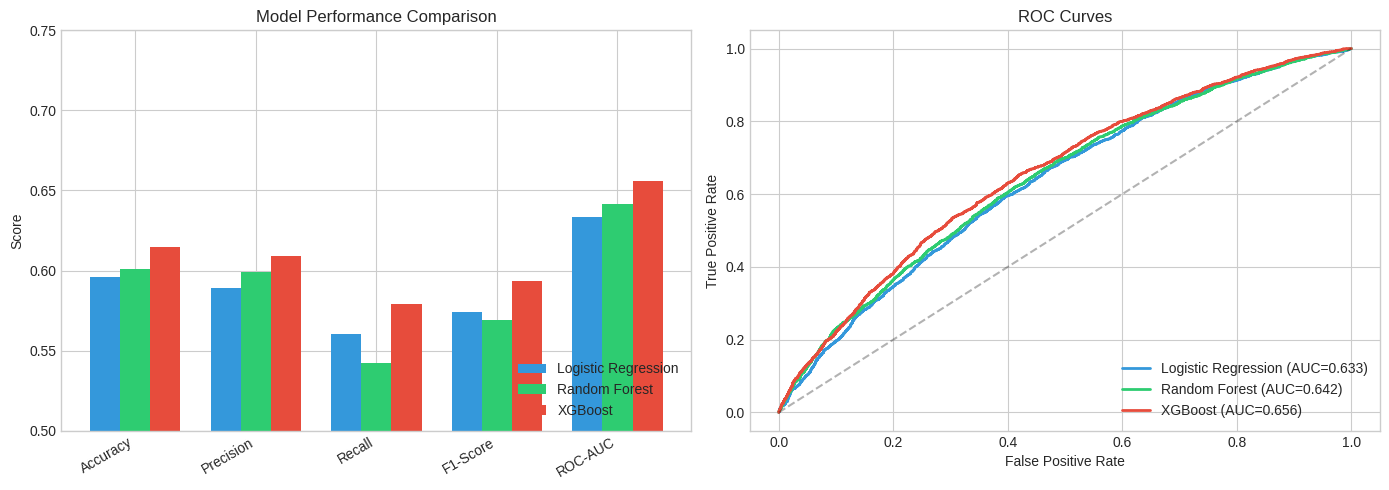

In [25]:
# Compare all models
results = pd.DataFrame({
    'Model': ['Logistic Regression', 'Random Forest', 'XGBoost'],
    'Accuracy': [lr_acc, rf_acc, xgb_acc],
    'Precision': [precision_score(y_test, lr_pred), precision_score(y_test, rf_pred), precision_score(y_test, xgb_pred)],
    'Recall': [recall_score(y_test, lr_pred), recall_score(y_test, rf_pred), recall_score(y_test, xgb_pred)],
    'F1-Score': [lr_f1, rf_f1, xgb_f1],
    'ROC-AUC': [lr_auc, rf_auc, xgb_auc]
}).round(4)

print('=== Model Comparison ===')
print(results.to_string(index=False))

# Visualize
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Metrics comparison
metrics = ['Accuracy', 'Precision', 'Recall', 'F1-Score', 'ROC-AUC']
x = np.arange(len(metrics))
width = 0.25

axes[0].bar(x - width, results.iloc[0][metrics], width, label='Logistic Regression', color='#3498db')
axes[0].bar(x, results.iloc[1][metrics], width, label='Random Forest', color='#2ecc71')
axes[0].bar(x + width, results.iloc[2][metrics], width, label='XGBoost', color='#e74c3c')
axes[0].set_xticks(x)
axes[0].set_xticklabels(metrics, rotation=30, ha='right')
axes[0].set_ylabel('Score')
axes[0].set_title('Model Performance Comparison')
axes[0].set_ylim(0.5, 0.75)
axes[0].legend(loc='lower right')

# ROC Curves
for name, proba, color in [('Logistic Regression', lr_proba, '#3498db'),
                            ('Random Forest', rf_proba, '#2ecc71'),
                            ('XGBoost', xgb_proba, '#e74c3c')]:
    fpr, tpr, _ = roc_curve(y_test, proba)
    auc = roc_auc_score(y_test, proba)
    axes[1].plot(fpr, tpr, label=f'{name} (AUC={auc:.3f})', color=color, linewidth=2)

axes[1].plot([0, 1], [0, 1], 'k--', alpha=0.3)
axes[1].set_xlabel('False Positive Rate')
axes[1].set_ylabel('True Positive Rate')
axes[1].set_title('ROC Curves')
axes[1].legend(loc='lower right')

plt.tight_layout()
plt.show()

##6.2 Confusion Matrix (XGBoost — Best Model)

True Negatives: 2491
False Positives: 1350
False Negatives: 1530
True Positives: 2103


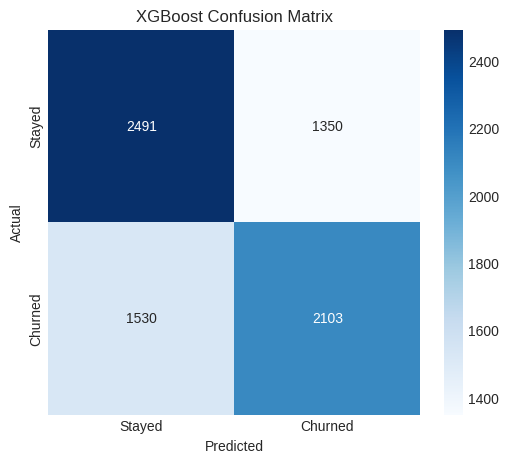

In [26]:
# Calculate confusion matrix
cm = confusion_matrix(
    y_test,
    xgb_pred,
    labels=[0, 1]
)

# Extract values
tn, fp, fn, tp = cm.ravel()

print("True Negatives:", tn)
print("False Positives:", fp)
print("False Negatives:", fn)
print("True Positives:", tp)


# Plot confusion matrix
plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Stayed', 'Churned'],
    yticklabels=['Stayed', 'Churned']
)

plt.title('XGBoost Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

##6.3 Feature Importance (XGBoost)
Understanding which features drive the model's predictions is essential for translating ML outputs into actionable business insights.

Top 15 Most Important Features:


,Feature,Gain
83,num__missingindicator_change_rev,15.832
76,num__eqpdays,14.112
48,num__months,12.902
250,cat__ethnic_Z,11.969
189,cat__refurb_new_N,11.171
82,num__missingindicator_change_mou,10.898
2,num__totmrc_Mean,10.840
49,num__uniqsubs,10.292
208,cat__infobase_Missing,10.062
224,cat__dwllsize_H,9.691


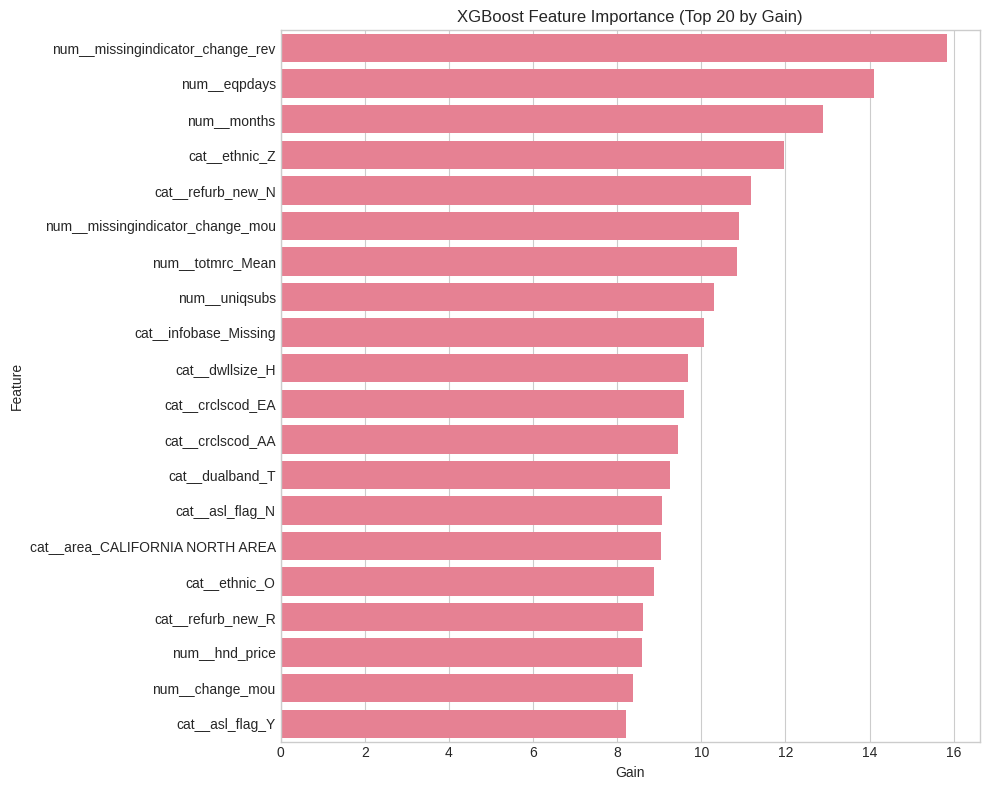

In [27]:
## Get feature importance using Gain
booster = xgb_model.get_booster()

gain_scores = booster.get_score(
    importance_type='gain'
)

# Match transformed feature names with XGBoost importance scores
importance = pd.DataFrame({
    'Feature': feature_names,
    'Gain': [
        gain_scores.get(f'f{i}', 0.0)
        for i in range(len(feature_names))
    ]
})

# Sort features by importance
importance = importance.sort_values(
    'Gain',
    ascending=False
)

# Display top 15 features
print('Top 15 Most Important Features:')
display(importance.head(15).round(3))


# Plot top 20 features
top20 = importance.head(20)

plt.figure(figsize=(10, 8))

sns.barplot(
    data=top20,
    x='Gain',
    y='Feature'
)

plt.title('XGBoost Feature Importance (Top 20 by Gain)')
plt.xlabel('Gain')
plt.ylabel('Feature')
plt.tight_layout()
plt.show()

### 6.3.1 Interpretation of Feature Importance

The XGBoost feature importance analysis highlights several important predictors.

Equipment age (`eqpdays`) and customer tenure (`months`) are among the most influential numerical features.

Missing-value indicators for `change_rev` and `change_mou` also have high importance, suggesting that missingness patterns contain predictive information.

Monthly recurring charges (`totmrc_Mean`) and the number of subscriptions (`uniqsubs`) also contribute to the model's predictions.

Some categorical features, including ethnicity, appear among the important predictors. Their use requires additional fairness and privacy considerations before any business deployment.

Feature importance indicates predictive contribution, not causation or the direction of a relationship.

### 6.4 ROC Curve Analysis

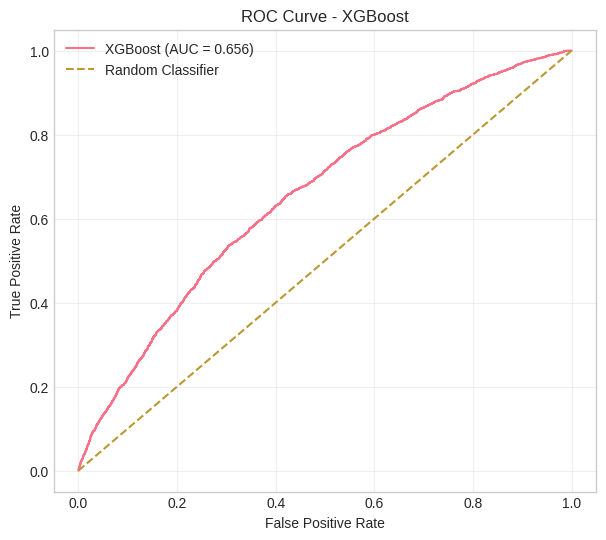

Test ROC-AUC: 0.6559


In [28]:
from sklearn.metrics import roc_curve, roc_auc_score

# Calculate ROC curve on the test set
fpr, tpr, roc_thresholds = roc_curve(y_test, xgb_proba)

test_auc = roc_auc_score(y_test, xgb_proba)

# Plot ROC curve
plt.figure(figsize=(7, 6))

plt.plot(
    fpr,
    tpr,
    label=f'XGBoost (AUC = {test_auc:.3f})'
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle='--',
    label='Random Classifier'
)

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve - XGBoost')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

print(f'Test ROC-AUC: {test_auc:.4f}')

##6.4.1
The ROC curve shows that XGBoost performs better than a random classifier, achieving an AUC of 0.6559.

This indicates a moderate ability to distinguish between customers who churn and those who stay. However, the model's discriminative performance is still limited and may require further improvement before practical deployment.

### 6.5 Classification Threshold Analysis

In [29]:
from sklearn.base import clone
from sklearn.metrics import precision_score, recall_score, f1_score

# Split the training data into training and validation subsets
X_train_part, X_val, y_train_part, y_val = train_test_split(
    X_train_fe,
    y_train,
    test_size=0.2,
    random_state=42,
    stratify=y_train
)

# Create a fresh preprocessing pipeline
val_preprocessor = clone(preprocessor)

# Fit preprocessing only on the training subset
X_train_part_processed = val_preprocessor.fit_transform(X_train_part)

# Transform validation data
X_val_processed = val_preprocessor.transform(X_val)


# Train XGBoost using the same settings
xgb_val_model = XGBClassifier(
    n_estimators=300,
    learning_rate=0.05,
    max_depth=6,
    min_child_weight=5,
    subsample=0.8,
    colsample_bytree=0.8,
    eval_metric='logloss',
    random_state=42,
    n_jobs=-1
)

xgb_val_model.fit(X_train_part_processed, y_train_part)

# Get churn probabilities for validation data
val_probabilities = xgb_val_model.predict_proba(
    X_val_processed
)[:, 1]


# Compare different classification thresholds
thresholds = [0.30, 0.35, 0.40, 0.45, 0.50, 0.55, 0.60, 0.65]

threshold_results = []

for threshold in thresholds:

    val_predictions = (
        val_probabilities >= threshold
    ).astype(int)

    precision = precision_score(
        y_val, val_predictions, zero_division=0
    )

    recall = recall_score(
        y_val, val_predictions, zero_division=0
    )

    f1 = f1_score(
        y_val, val_predictions, zero_division=0
    )

    customers_targeted = int(val_predictions.sum())

    threshold_results.append({
        'Threshold': threshold,
        'Precision': precision,
        'Recall': recall,
        'F1-Score': f1,
        'Customers Targeted': customers_targeted,
        'Targeted Percentage': (
            customers_targeted / len(y_val) * 100
        )
    })


threshold_df = pd.DataFrame(threshold_results)

display(threshold_df.round(4))

,Threshold,Precision,Recall,F1-Score,Customers Targeted,Targeted Percentage
0,0.30,0.5090,0.9133,0.6537,3041,87.1846
1,0.35,0.5261,0.8572,0.6520,2762,79.1858
2,0.40,0.5457,0.7817,0.6427,2428,69.6101
3,0.45,0.5661,0.6920,0.6228,2072,59.4037
4,0.50,0.5915,0.5776,0.5845,1655,47.4484
5,0.55,0.6167,0.4631,0.5290,1273,36.4966
6,0.60,0.6411,0.3593,0.4605,950,27.2362
7,0.65,0.6626,0.2549,0.3681,652,18.6927


### 6.6 Evaluation at the Selected Threshold

Based on validation results, a threshold of 0.35 is selected as a provisional operating point.

The model is evaluated on the test set using this threshold to examine its precision, recall, F1-score, and customer targeting rate.

Selected Threshold: 0.35
Accuracy: 0.5732
Precision: 0.5378
Recall: 0.8668
F1-Score: 0.6638
Customers Targeted: 5855
Targeted Percentage: 78.34%

True Negatives: 1135
False Positives: 2706
False Negatives: 484
True Positives: 3149


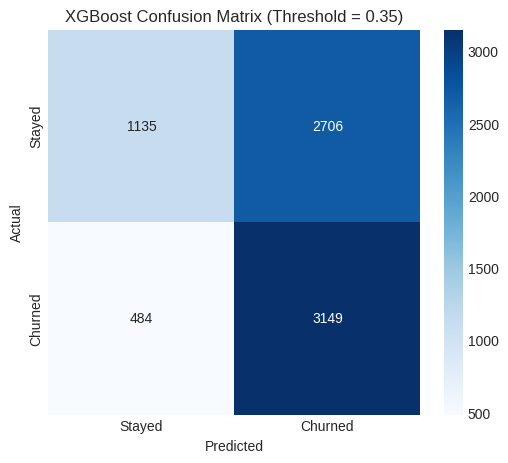

In [30]:
# Provisional threshold selected using validation data
selected_threshold = 0.35

# Generate predictions using the selected threshold
xgb_pred_selected = (
    xgb_proba >= selected_threshold
).astype(int)

# Calculate evaluation metrics
selected_accuracy = accuracy_score(y_test, xgb_pred_selected)
selected_precision = precision_score(y_test, xgb_pred_selected)
selected_recall = recall_score(y_test, xgb_pred_selected)
selected_f1 = f1_score(y_test, xgb_pred_selected)

# Calculate number of targeted customers
customers_targeted = int(xgb_pred_selected.sum())
targeted_percentage = customers_targeted / len(y_test) * 100

print(f"Selected Threshold: {selected_threshold}")
print(f"Accuracy: {selected_accuracy:.4f}")
print(f"Precision: {selected_precision:.4f}")
print(f"Recall: {selected_recall:.4f}")
print(f"F1-Score: {selected_f1:.4f}")
print(f"Customers Targeted: {customers_targeted}")
print(f"Targeted Percentage: {targeted_percentage:.2f}%")


# Confusion Matrix
cm_selected = confusion_matrix(
    y_test,
    xgb_pred_selected,
    labels=[0, 1]
)

tn, fp, fn, tp = cm_selected.ravel()

print("\nTrue Negatives:", tn)
print("False Positives:", fp)
print("False Negatives:", fn)
print("True Positives:", tp)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm_selected,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Stayed', 'Churned'],
    yticklabels=['Stayed', 'Churned']
)

plt.title(f'XGBoost Confusion Matrix (Threshold = {selected_threshold})')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

### 6.6.1 Business Interpretation of the Selected Threshold

At a classification threshold of 0.35, XGBoost achieved a recall of 86.68% and a precision of 53.78% on the test set.

The model identified 3,149 out of 3,633 actual churners, while missing 484 customers.

However, it classified 2,706 customers who stayed as potential churners. Overall, 78.34% of the test customers were flagged for retention intervention.

This threshold prioritizes churn detection over minimizing intervention volume. Its practical suitability depends on the company's retention budget and intervention costs.

### 6.7 Feature Ablation: Excluding Ethnicity

Since ethnicity is a sensitive feature, we evaluate a second XGBoost model without using it as a predictive input.

Both models will be trained and evaluated on the same training and validation split to compare their performance fairly.

The ethnicity column will only be retained separately for fairness analysis, not as a model input.

In [ ]:
# Remove ethnicity from model inputs
X_train_part_no_eth = X_train_part.drop(columns=['ethnic'])
X_val_no_eth = X_val.drop(columns=['ethnic'])


# Identify numerical and categorical columns
numeric_cols_no_eth = X_train_part_no_eth.select_dtypes(
    include=['number']
).columns.tolist()

categorical_cols_no_eth = X_train_part_no_eth.select_dtypes(
    include=['object', 'category']
).columns.tolist()


# Create numerical preprocessing
numeric_transformer_no_eth = Pipeline(steps=[
    ('imputer', SimpleImputer(
        strategy='median',
        add_indicator=True
    )),
    ('scaler', StandardScaler())
])


# Create categorical preprocessing
categorical_transformer_no_eth = Pipeline(steps=[
    ('imputer', SimpleImputer(
        strategy='constant',
        fill_value='Missing'
    )),
    ('encoder', OneHotEncoder(
        handle_unknown='ignore'
    ))
])


# Combine preprocessing steps
preprocessor_no_eth = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer_no_eth, numeric_cols_no_eth),
        ('cat', categorical_transformer_no_eth, categorical_cols_no_eth)
    ],
    remainder='drop'
)


# Fit preprocessing on training subset only
X_train_part_no_eth_processed = (
    preprocessor_no_eth.fit_transform(X_train_part_no_eth)
)

# Transform validation subset
X_val_no_eth_processed = (
    preprocessor_no_eth.transform(X_val_no_eth)
)


# Train XGBoost without ethnicity
xgb_no_eth = XGBClassifier(
    n_estimators=300,
    learning_rate=0.05,
    max_depth=6,
    min_child_weight=5,
    subsample=0.8,
    colsample_bytree=0.8,
    eval_metric='logloss',
    random_state=42,
    n_jobs=-1
)

xgb_no_eth.fit(
    X_train_part_no_eth_processed,
    y_train_part
)


# Get validation probabilities
no_eth_val_proba = xgb_no_eth.predict_proba(
    X_val_no_eth_processed
)[:, 1]


print("Original processed features:", X_train_part_processed.shape[1])
print("Features without ethnicity:", X_train_part_no_eth_processed.shape[1])

In [ ]:
# Compare both models on the same validation set
comparison_results = []

models_probabilities = {
    'With Ethnicity': val_probabilities,
    'Without Ethnicity': no_eth_val_proba
}

for model_name, probabilities in models_probabilities.items():

    for threshold in [0.35, 0.50]:

        predictions = (
            probabilities >= threshold
        ).astype(int)

        comparison_results.append({
            'Model': model_name,
            'Threshold': threshold,
            'Accuracy': accuracy_score(y_val, predictions),
            'Precision': precision_score(
                y_val, predictions, zero_division=0
            ),
            'Recall': recall_score(
                y_val, predictions, zero_division=0
            ),
            'F1-Score': f1_score(
                y_val, predictions, zero_division=0
            ),
            'ROC-AUC': roc_auc_score(
                y_val, probabilities
            ),
            'Targeted Customers': int(predictions.sum())
        })


comparison_df = pd.DataFrame(comparison_results)

display(comparison_df.round(4))

### 6.8 Fairness Analysis

Although ethnicity was excluded from the second model, we retain the original ethnicity labels separately for evaluation purposes.

We compare recall, false positive rate, precision, and prediction rates across ethnicity groups to identify potential differences in model performance.

This analysis is intended as an initial fairness audit and does not by itself establish that the model is fair.

In [ ]:
def calculate_group_metrics(
    y_true,
    probabilities,
    sensitive_groups,
    model_name,
    threshold
):
    y_true = pd.Series(y_true).copy()

    probabilities = pd.Series(
        np.asarray(probabilities),
        index=y_true.index
    )

    groups = pd.Series(
        sensitive_groups,
        index=y_true.index
    ).fillna('Missing').astype(str)

    predictions = (probabilities >= threshold).astype(int)

    results = []

    for group in sorted(groups.unique()):

        mask = groups == group

        actual = y_true.loc[mask].astype(int)
        predicted = predictions.loc[mask]

        tn, fp, fn, tp = confusion_matrix(
            actual,
            predicted,
            labels=[0, 1]
        ).ravel()

        recall = tp / (tp + fn) if (tp + fn) else np.nan

        fpr = fp / (fp + tn) if (fp + tn) else np.nan

        precision = tp / (tp + fp) if (tp + fp) else np.nan

        results.append({
            'Model': model_name,
            'Threshold': threshold,
            'Ethnicity Group': group,
            'Customers': len(actual),
            'Actual Churn Rate': actual.mean(),
            'Recall': recall,
            'False Positive Rate': fpr,
            'Precision': precision,
            'Targeted Rate': predicted.mean()
        })

    return results


# Compare both models using the same validation customers
fairness_results = []

models_for_audit = {
    'With Ethnicity': val_probabilities,
    'Without Ethnicity': no_eth_val_proba
}

for model_name, probabilities in models_for_audit.items():

    for threshold in [0.35, 0.50]:

        fairness_results.extend(
            calculate_group_metrics(
                y_true=y_val,
                probabilities=probabilities,
                sensitive_groups=X_val['ethnic'],
                model_name=model_name,
                threshold=threshold
            )
        )


fairness_df = pd.DataFrame(fairness_results)

display(
    fairness_df.sort_values(
        ['Threshold', 'Model', 'Ethnicity Group']
    ).round(4)
)

In [ ]:
# Focus on the selected threshold
fairness_035 = fairness_df[
    fairness_df['Threshold'] == 0.35
].copy()

# Flag groups with small validation samples
fairness_035['Sample Size Note'] = np.where(
    fairness_035['Customers'] < 50,
    'Small sample - unstable',
    'Review sample size'
)

# Display all groups without truncation
fairness_035 = fairness_035.sort_values(
    ['Ethnicity Group', 'Model']
)

display(
    fairness_035.round(4).reset_index(drop=True)
)

In [ ]:
# Groups with at least 100 validation customers
larger_groups = fairness_035[
    fairness_035['Customers'] >= 100
].copy()

display(
    larger_groups[
        [
            'Model',
            'Ethnicity Group',
            'Customers',
            'Actual Churn Rate',
            'Recall',
            'False Positive Rate',
            'Precision',
            'Targeted Rate'
        ]
    ].round(4).reset_index(drop=True)
)

In [ ]:
# Select threshold 0.35 and the required columns
fairness_035 = fairness_df.loc[
    fairness_df['Threshold'] == 0.35,
    [
        'Model',
        'Threshold',
        'Ethnicity Group',
        'Customers',
        'Actual Churn Rate',
        'Recall',
        'False Positive Rate',
        'Precision',
        'Targeted Rate'
    ]
].copy()

# Keep groups with at least 100 customers
large_groups = fairness_035[
    fairness_035['Customers'] >= 100
].copy()

# Sort and display all rows
large_groups = large_groups.sort_values(
    ['Ethnicity Group', 'Model']
)

display(
    large_groups.round(4).reset_index(drop=True)
)

In [ ]:
metrics = [
    'Recall',
    'False Positive Rate',
    'Precision',
    'Targeted Rate'
]

fairness_comparison = large_groups.pivot(
    index='Ethnicity Group',
    columns='Model',
    values=metrics
)

display(fairness_comparison.round(4))

### 6.8.1 Fairness Analysis Conclusion

Excluding ethnicity resulted in very limited changes to overall model performance.

The recall gap across the evaluated groups decreased from 31.16 to 8.75 percentage points, while the false positive rate gap decreased from 29.70 to 13.67 percentage points.

The targeted rate gap also decreased from 32.21 to 5.68 percentage points. However, the precision gap increased slightly.

Based on these findings, the XGBoost model without ethnicity is selected as the preferred candidate for the business proposal.

This is an initial fairness assessment rather than proof of complete fairness. Further monitoring would be required before real-world deployment.

### 6.9 Final Model Selection

Based on the model comparison and the initial fairness assessment, XGBoost without ethnicity is selected as the preferred model candidate.

The preprocessing pipeline is fitted on the full training set, and the selected model is evaluated on the test set using the provisional classification threshold of 0.35.

In [ ]:
# 1. Remove ethnicity from model inputs
X_train_final = X_train_fe.drop(columns=['ethnic']).copy()
X_test_final = X_test_fe.drop(columns=['ethnic']).copy()


# 2. Identify numerical and categorical columns
numeric_cols_final = X_train_final.select_dtypes(
    include=['number']
).columns.tolist()

categorical_cols_final = X_train_final.select_dtypes(
    include=['object', 'category']
).columns.tolist()


# 3. Build the final preprocessing pipeline
numeric_transformer_final = Pipeline(steps=[
    ('imputer', SimpleImputer(
        strategy='median',
        add_indicator=True
    )),
    ('scaler', StandardScaler())
])

categorical_transformer_final = Pipeline(steps=[
    ('imputer', SimpleImputer(
        strategy='constant',
        fill_value='Missing'
    )),
    ('encoder', OneHotEncoder(
        handle_unknown='ignore'
    ))
])

final_preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer_final, numeric_cols_final),
        ('cat', categorical_transformer_final, categorical_cols_final)
    ]
)


# 4. Fit preprocessing on training data only
X_train_final_processed = final_preprocessor.fit_transform(
    X_train_final
)

X_test_final_processed = final_preprocessor.transform(
    X_test_final
)


# 5. Train final XGBoost model
xgb_final_model = XGBClassifier(
    n_estimators=300,
    learning_rate=0.05,
    max_depth=6,
    min_child_weight=5,
    subsample=0.8,
    colsample_bytree=0.8,
    eval_metric='logloss',
    random_state=42,
    n_jobs=-1
)

xgb_final_model.fit(
    X_train_final_processed,
    y_train
)


# 6. Predict probabilities
final_proba = xgb_final_model.predict_proba(
    X_test_final_processed
)[:, 1]


# 7. Apply the selected threshold
final_threshold = 0.35

final_pred = (
    final_proba >= final_threshold
).astype(int)


# 8. Evaluate the final model
print("=== Final XGBoost Model (Without Ethnicity) ===")
print(f"Threshold: {final_threshold}")
print(f"Accuracy:  {accuracy_score(y_test, final_pred):.4f}")
print(f"Precision: {precision_score(y_test, final_pred):.4f}")
print(f"Recall:    {recall_score(y_test, final_pred):.4f}")
print(f"F1-Score:  {f1_score(y_test, final_pred):.4f}")
print(f"ROC-AUC:   {roc_auc_score(y_test, final_proba):.4f}")


# 9. Confusion matrix
final_cm = confusion_matrix(
    y_test,
    final_pred,
    labels=[0, 1]
)

tn_final, fp_final, fn_final, tp_final = final_cm.ravel()

print("\nTrue Negatives:", tn_final)
print("False Positives:", fp_final)
print("False Negatives:", fn_final)
print("True Positives:", tp_final)

print("\nCustomers targeted:", int(final_pred.sum()))
print(
    "Targeted percentage:",
    f"{final_pred.mean() * 100:.2f}%"
)


# 10. Verify processed data
print("\nProcessed features:", X_train_final_processed.shape[1])
print("Training NaNs:", count_nan_values(X_train_final_processed))
print("Testing NaNs:", count_nan_values(X_test_final_processed))

##7. Business Proposal: Data-Driven Retention Strategy

##7.1 Key Findings from the Analysis
Based on our EDA and modeling, we identified the following actionable insights:

High-value customers (top 25% by revenue) represent ~25% of the customer base but generate a disproportionate share of lifetime revenue. Retaining them should be Company A's top priority.

Equipment age is the #1 churn predictor. Customers with equipment older than 2 years have a churn rate of ~59%, compared to ~43% for those with equipment under 6 months. This suggests that device upgrade programs could significantly reduce churn.

Revenue and usage trends are strong signals. Customers showing declining usage or revenue change patterns are at higher risk — these can be detected months before actual churn.

Call quality matters. Higher rates of dropped and blocked calls correlate with churn, indicating network quality issues in certain areas may be driving customers away.

Geographic variation exists. Some areas show significantly higher churn rates among high-value customers, suggesting regional competitive pressure or service quality differences.

##7.2 Proposed Retention Interventions
Based on the model findings, we propose a tiered retention strategy using the XGBoost model to identify at-risk high-value customers and deploy targeted interventions

##7.3 Revenue Impact Quantification
We estimate the financial impact of deploying the XGBoost-based retention strategy.

In [ ]:
# Final Business Impact Analysis
# Based on the final XGBoost model without ethnicity

# High-Value Customer Base
n_hv = len(hv)
hv_churn_rate = hv['churn'].mean()
n_hv_churned = int(hv['churn'].sum())
avg_monthly_rev_hv = hv['rev_Mean'].mean()
annual_rev_per_customer = avg_monthly_rev_hv * 12

# Final Model Performance (Test Set)
model_recall = 0.8737
model_precision = 0.5405
test_targeting_rate = 0.7857

# Business Assumptions
intervention_success_rate = 0.30
cost_per_targeted_customer = 100

# Estimated Customers Targeted
estimated_customers_targeted = int(n_hv * test_targeting_rate)

# Estimated Churners Detected
estimated_detected_churners = int(n_hv_churned * model_recall)

# Estimated Customers Retained
estimated_customers_saved = int(
    estimated_detected_churners * intervention_success_rate
)

# Financial Impact
gross_revenue_preserved = (
    estimated_customers_saved * annual_rev_per_customer
)

campaign_cost = (
    estimated_customers_targeted * cost_per_targeted_customer
)

revenue_after_campaign_cost = gross_revenue_preserved - campaign_cost

revenue_to_cost_ratio = gross_revenue_preserved / campaign_cost

revenue_based_roi_proxy = (
    revenue_after_campaign_cost / campaign_cost * 100
)

# Revenue at Risk
annual_revenue_at_risk = (
    n_hv_churned * annual_rev_per_customer
)

percentage_of_at_risk_revenue_preserved = (
    gross_revenue_preserved / annual_revenue_at_risk * 100
)

# Display Results
print("=" * 60)
print("FINAL BUSINESS IMPACT ANALYSIS")
print("=" * 60)

print("\nHigh-Value Customer Base:")
print(f"Total HV customers: {n_hv:,}")
print(f"HV churn rate: {hv_churn_rate:.2%}")
print(f"HV customers churning: {n_hv_churned:,}")
print(f"Average monthly revenue: ${avg_monthly_rev_hv:.2f}")
print(f"Average annual revenue: ${annual_rev_per_customer:.2f}")

print("\nFinal XGBoost Performance:")
print(f"Model Recall: {model_recall:.2%}")
print(f"Model Precision: {model_precision:.2%}")
print(f"Test targeting rate: {test_targeting_rate:.2%}")

print("\nRetention Program Estimates:")
print(f"Estimated customers targeted: {estimated_customers_targeted:,}")
print(f"Estimated detected churners: {estimated_detected_churners:,}")
print(f"Intervention success rate: {intervention_success_rate:.0%}")
print(f"Estimated customers retained: {estimated_customers_saved:,}")

print("\nAnnual Financial Impact:")
print(f"Gross revenue preserved: ${gross_revenue_preserved:,.0f}")
print(f"Campaign intervention cost: ${campaign_cost:,.0f}")
print(f"Revenue less campaign cost: ${revenue_after_campaign_cost:,.0f}")
print(f"Revenue / Campaign Cost: {revenue_to_cost_ratio:.2f}x")
print(f"Revenue-based ROI proxy: {revenue_based_roi_proxy:.1f}%")

print("\nRevenue at Risk:")
print(f"Annual revenue at risk: ${annual_revenue_at_risk:,.0f}")
print(
    f"Percentage of at-risk revenue preserved: "
    f"{percentage_of_at_risk_revenue_preserved:.2f}%"
)

In [ ]:
import matplotlib.pyplot as plt

# ==============================
# Business Impact Visualization
# ==============================

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# ------------------------------
# 1. Annual Financial Impact
# ------------------------------
financial_labels = [
    'Revenue at Risk',
    'Gross Revenue\nPreserved',
    'Campaign Cost',
    'Revenue After\nCampaign Cost'
]

financial_values = [
    annual_revenue_at_risk,
    gross_revenue_preserved,
    campaign_cost,
    revenue_after_campaign_cost
]

financial_values_millions = [
    value / 1_000_000 for value in financial_values
]

bars1 = axes[0].bar(
    financial_labels,
    financial_values_millions
)

axes[0].set_title('Estimated Annual Financial Impact')
axes[0].set_ylabel('Amount ($ Millions)')
axes[0].tick_params(axis='x', rotation=15)

for bar, value in zip(bars1, financial_values_millions):
    axes[0].text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f'${value:.2f}M',
        ha='center',
        va='bottom',
        fontsize=9
    )

# ------------------------------
# 2. Retention Program Estimates
# ------------------------------
retention_labels = [
    'High-Value\nCustomers',
    'Customers\nTargeted',
    'Detected\nChurners',
    'Estimated\nCustomers Retained'
]

retention_values = [
    n_hv,
    estimated_customers_targeted,
    estimated_detected_churners,
    estimated_customers_saved
]

bars2 = axes[1].bar(
    retention_labels,
    retention_values
)

axes[1].set_title('Estimated Retention Program Outcomes')
axes[1].set_ylabel('Number of Customers')

for bar, value in zip(bars2, retention_values):
    axes[1].text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f'{value:,}',
        ha='center',
        va='bottom',
        fontsize=9
    )

# ------------------------------
# Overall Figure
# ------------------------------
fig.suptitle(
    'High-Value Customer Retention: Business Impact',
    fontsize=15,
    fontweight='bold'
)

plt.tight_layout()
plt.show()

## 7.4 Implementation Roadmap
### Implementation Roadmap

**Phase 1: Preparation & Setup**
- Integrate the churn prediction model into the customer analytics workflow.
- Define retention campaign objectives, budget, and eligibility criteria.
- Prepare targeted retention offers and customer communication strategies.

**Phase 2: Controlled Pilot**
- Launch a pilot targeting selected high-value customers identified by the model.
- Apply retention interventions using predefined campaign rules.
- Track campaign costs, customer responses, and retention outcomes.

**Phase 3: Evaluation**
- Compare the pilot group against an appropriate control group.
- Measure incremental retention, revenue impact, and intervention costs.
- Evaluate model performance and monitor fairness across customer groups.

**Phase 4: Gradual Expansion**
- Expand the campaign only if the pilot demonstrates positive incremental business value.
- Refine targeting thresholds and retention strategies based on observed results.
- Continue monitoring model performance, customer experience, and campaign effectiveness.

## 7.5 Assumptions & Limitations

### Assumptions

- A 30% intervention success rate is used as a scenario assumption. It has not been validated using this dataset.
- The average intervention cost is assumed to be $100 per targeted customer.
- Retained customers are assumed to continue generating revenue at the same average monthly rate for 12 months.
- Average monthly revenue across the high-value segment is used as a proxy for the revenue generated by retained customers.
- Model recall and targeting rates from the test evaluation are assumed to generalize to the full high-value customer segment.

### Limitations

- The model achieves a ROC-AUC of 0.6587, indicating moderate predictive discrimination.
- At the selected threshold of 0.35, approximately 78.57% of test customers are flagged for intervention, which may require a substantial retention budget.
- The estimated financial impact represents gross revenue preservation, not net profit.
- The 30% intervention success rate and $100 intervention cost are assumptions that require validation through a pilot.
- The test dataset was used during earlier model comparisons, so the final results are development estimates rather than a fully independent external evaluation.
- Excluding ethnicity from model inputs does not guarantee complete fairness. Group-level performance should continue to be monitored.
- The dataset does not capture all external factors affecting churn, such as competitor offers, economic conditions, or changes in service quality.
- The model predicts churn within the 31–60 day observation window, and actual intervention lead times may vary.

## 7.6 Conclusion

This project developed a machine learning approach to identify high-value telecommunications customers who are at risk of churn.

The analysis identified 24,913 high-value customers, representing approximately 25% of the customer base. This segment contributes a substantial share of company revenue and has a churn rate of 48.61%.

Three machine learning models were evaluated: Logistic Regression, Random Forest, and XGBoost. XGBoost was selected as the preferred candidate based on its overall predictive performance. The final model excluded ethnicity from its predictive inputs and achieved the following results on the test set:

- Accuracy: 57.76%
- Precision: 54.05%
- Recall: 87.37%
- F1-score: 66.79%
- ROC-AUC: 65.87%

Using a classification threshold of 0.35, the model identified 3,174 actual churners in the test set while targeting approximately 78.57% of customers.

The business impact scenario estimated approximately $$4.34 million in gross annual revenue preservation against an estimated campaign cost of $1.96 million. This represents a revenue-to-campaign-cost ratio of 2.22x under the stated assumptions, rather than verified profit or realized ROI.

The recommended next step is to conduct a controlled pilot to measure the actual effectiveness of retention interventions, validate campaign costs and retention outcomes, and monitor model performance and fairness before wider deployment.

Overall, this project demonstrates how customer analytics and machine learning can support a more targeted customer-retention strategy for Company A.

### References

1. **GCI World (2026).** *Final Assignment Tutorial – Telecom Churn Prediction.* Course-provided tutorial and project guidelines.

2. **Company A.** *Client.csv and Record.csv.* Anonymized telecommunications customer datasets provided for the final assignment.

3. **Pandas Development Team.** *Pandas Documentation.* https://pandas.pydata.org/docs/

4. **NumPy Developers.** *NumPy Documentation.* https://numpy.org/doc/stable/

5. **Matplotlib Development Team.** *Matplotlib Documentation.* https://matplotlib.org/stable/

6. **Seaborn Development Team.** *Seaborn Documentation.* https://seaborn.pydata.org/

7. **Scikit-learn Developers.** *Scikit-learn Documentation.* https://scikit-learn.org/stable/

8. **XGBoost Developers.** *XGBoost Documentation.* https://xgboost.readthedocs.io/en/stable/

9. **Google.** *Google Colab.* https://colab.research.google.com/

**Accessed:** November 2026.